In [1]:
pip install torch pandas numpy scikit-learn matplotlib seaborn tqdm

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install shap lime dice-ml

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install lime


Note: you may need to restart the kernel to use updated packages.


In [4]:
# 'dataset_paths':["/kaggle/input/nbaiot-dataset/1.benign.csv","/kaggle/input/nbaiot-dataset/1.gafgyt.combo.csv"
# ,"/kaggle/input/nbaiot-dataset/1.gafgyt.junk.csv",
# "/kaggle/input/nbaiot-dataset/1.gafgyt.tcp.csv",
# "/kaggle/input/nbaiot-dataset/1.mirai.udp.csv",
# "/kaggle/input/nbaiot-dataset/1.mirai.scan.csv",
# "/kaggle/input/nbaiot-dataset/1.mirai.syn.csv",
# "/kaggle/input/nbaiot-dataset/1.mirai.udpplain.csv"
# ,"/kaggle/input/nbaiot-dataset/1.mirai.ack.csv",
#                     "/kaggle/input/nbaiot-dataset/2.benign.csv","/kaggle/input/nbaiot-dataset/2.gafgyt.combo.csv"
# ,"/kaggle/input/nbaiot-dataset/2.gafgyt.junk.csv",
# "/kaggle/input/nbaiot-dataset/2.gafgyt.tcp.csv",
# "/kaggle/input/nbaiot-dataset/2.mirai.udp.csv",
# "/kaggle/input/nbaiot-dataset/2.mirai.scan.csv",
# "/kaggle/input/nbaiot-dataset/2.mirai.syn.csv",
# "/kaggle/input/nbaiot-dataset/2.mirai.udpplain.csv"
# ,"/kaggle/input/nbaiot-dataset/2.mirai.ack.csv"

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader , WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from tqdm import tqdm
# Set seeds
np.random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

#%% [markdown]
# ## 1. Configuration and Attack Mapping

#%%

CONFIG = {
    'batch_size': 512,
    'epochs': 30,
    'learning_rate': 0.001,
    'input_shape': (115, 1), # (Features, Channels)
    'use_mock_data': False, # Set to False and provide path below for real data
    # 'dataset_path': '/kaggle/input/CICIOT23/',
    'dataset_paths':["/kaggle/input/1.benign.csv","/kaggle/input/1.gafgyt.combo.csv"
,"/kaggle/input/1.gafgyt.junk.csv",
"/kaggle/input/1.gafgyt.tcp.csv",
"/kaggle/input/1.mirai.udp.csv",
"/kaggle/input/1.mirai.scan.csv",
"/kaggle/input/1.mirai.syn.csv",
"/kaggle/input/1.mirai.udpplain.csv"
,"/kaggle/input/1.mirai.ack.csv",

                    ],
    "labels": [
        "benign",
        "Gafgyt_Combo",
        "Gafgyt_Junk",
        "Gafgyt_TCP",
        "Mirai_UDP",
        "Mirai_Scan",
        "Mirai_SYN",
        "Mirai_UDPPlain",
        "Mirai_ACK",
    ],
    "temperature":2.0,
    'ae_loss_weight': 0.1 
}

# --- Detailed Mapping Strategy (From User Request) ---

ATTACK_MAPPING = {
   'normal':"Normal",
    "injection":"Injection",
    "scanning":"Scanning",
    "password":"Password",
    "ransomware":"Ransomware",
    'xss':"XSS",
    'backdoor':"Backdoor",
    'dos':"Dos",
    'ddos':"DDos",
    'mitm':'Mitm'
}


Using device: cuda


In [2]:
full_data=pd.DataFrame()
for i,j in enumerate(CONFIG["dataset_paths"]):
    df1=pd.read_csv(j)
    df2=pd.read_csv(j.replace("1","2"))
    df1["label"]=CONFIG["labels"][i]
    df2["label"]=CONFIG["labels"][i]
    df=pd.concat([df1,df2], ignore_index=True)
    full_data=pd.concat([full_data,df], ignore_index=True)
    

In [3]:
full_data.size

183995256

In [4]:
full_data["label"].value_counts().keys()

Index(['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP', 'Mirai_UDPPlain',
       'Mirai_Scan', 'Gafgyt_Combo', 'benign', 'Gafgyt_Junk'],
      dtype='object', name='label')

In [5]:

SEEN_CLASSES = ['Mirai_UDP','Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP',
        'Gafgyt_Combo', 'benign','Gafgyt_Junk','Mirai_UDPPlain']
UNSEEN_CLASSES = ['Mirai_Scan']

print(f"Training on: {SEEN_CLASSES}")
print(f"Testing detection of: {UNSEEN_CLASSES}")

Training on: ['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP', 'Gafgyt_Combo', 'benign', 'Gafgyt_Junk', 'Mirai_UDPPlain']
Testing detection of: ['Mirai_Scan']


In [6]:
    CONFIG

{'batch_size': 512,
 'epochs': 30,
 'learning_rate': 0.001,
 'input_shape': (115, 1),
 'use_mock_data': False,
 'dataset_paths': ['/kaggle/input/1.benign.csv',
  '/kaggle/input/1.gafgyt.combo.csv',
  '/kaggle/input/1.gafgyt.junk.csv',
  '/kaggle/input/1.gafgyt.tcp.csv',
  '/kaggle/input/1.mirai.udp.csv',
  '/kaggle/input/1.mirai.scan.csv',
  '/kaggle/input/1.mirai.syn.csv',
  '/kaggle/input/1.mirai.udpplain.csv',
  '/kaggle/input/1.mirai.ack.csv'],
 'labels': ['benign',
  'Gafgyt_Combo',
  'Gafgyt_Junk',
  'Gafgyt_TCP',
  'Mirai_UDP',
  'Mirai_Scan',
  'Mirai_SYN',
  'Mirai_UDPPlain',
  'Mirai_ACK'],
 'temperature': 2.0,
 'ae_loss_weight': 0.1}

In [7]:
class IoTDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [8]:
config=CONFIG

In [9]:
# add the balance of the classes in the training of the data 

In [10]:


def load_and_process(config):
    try:
        
        X = full_data.drop(['label'], axis=1).values
        y = full_data['label'].values
        # Scale
        scaler = StandardScaler()
        X = scaler.fit_transform(X)
        # Reshape for Sequence: (Samples, Features, 1) -> PyTorch will need (Batch, Channels, Length) later
        X = X.reshape(X.shape[0], X.shape[1], 1)
    
        return X, y, full_data['label'].values


    except FileNotFoundError:
        print(f"File not found at {config['dataset_path']}. Check path.")
        return None, None, None
    except Exception as e:
        print(f"An error occurred: {e}")
        return None, None, None

X, y, y_raw = load_and_process(CONFIG)

#%% [markdown]
# ## 3. Splitting: Training (Seen Only) vs Testing (Mixed)

#%%
seen_indices = np.isin(y, SEEN_CLASSES)
unseen_indices = ~seen_indices

X_seen = X[seen_indices]
y_seen = y[seen_indices]

le = LabelEncoder()
y_seen_enc = le.fit_transform(y_seen)
num_classes = len(le.classes_)

X_train, X_temp, y_train, y_temp = train_test_split(X_seen, y_seen_enc, test_size=0.3, random_state=42, stratify=y_seen_enc)
X_val, X_test_seen, y_val, y_test_seen = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

X_unseen = X[unseen_indices]
y_unseen = y[unseen_indices]

y_test_seen_str = le.inverse_transform(y_test_seen)
X_test_final = np.concatenate([X_test_seen, X_unseen])
y_test_final_str = np.concatenate([y_test_seen_str, y_unseen])

y_train_tensor = y_train
y_val_tensor = y_val
y_test_dummy = np.zeros(len(X_test_final))

train_dataset = IoTDataset(X_train, y_train_tensor)
val_dataset = IoTDataset(X_val, y_val_tensor)
test_dataset = IoTDataset(X_test_final, y_test_dummy)

# --- WeightedRandomSampler Implementation ---
print("\nPreparing WeightedRandomSampler...")
# 1. Compute weight for each class: w_j = 1 / count_j
# Note: We use the same logic as compute_class_weight but manually to map to samples
class_counts = np.bincount(y_train)
class_weights_val = 1. / class_counts
# 2. Assign weight to each sample
sample_weights = class_weights_val[y_train]
# 3. Create Sampler
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# OPTIMIZATION: sampler added, shuffle must be False
train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], sampler=sampler, shuffle=False, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)

print(f"Training Samples: {len(X_train)}")
print(f"Validation Samples: {len(X_val)}")
print(f"Test Samples (Total): {len(X_test_final)}")



Preparing WeightedRandomSampler...
Training Samples: 1004702
Validation Samples: 215293
Test Samples (Total): 366171


In [11]:
len(X_unseen)


150877

In [12]:
class CNNTransformerBiLSTM(nn.Module):
    def __init__(self, input_len, num_classes):
        super(CNNTransformerBiLSTM, self).__init__()
        
        # 1. CNN Layers (Spatial Features)
        # Input shape: (Batch, 1, Features)
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=128, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2) 
        self.conv2 = nn.Conv1d(in_channels=128, out_channels=256, kernel_size=3, padding=1)
        
        # 2. Transformer Layer (Contextual Features)
        encoder_layer = nn.TransformerEncoderLayer(d_model=256, nhead=4, dim_feedforward=256, dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        
        # 3. BiLSTM Layer (Temporal Features - Replaces paper's RNN)
        # Input size is 128 from Transformer
        self.lstm = nn.LSTM(input_size=256, hidden_size=64, bidirectional=True, batch_first=True)
        
        # 4. Classifier
        # Input = 64 * 2 (Bidirectional)
        self.fc1 = nn.Linear(64*2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out = nn.Linear(64, num_classes)
        
    def forward(self, x):
        x = x.permute(0, 2, 1) 
        
        # --- CNN Block ---
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x)) 
        
        # --- Transformer Block ---
        # Transformer expects (Batch, Sequence Length, Features/Channels)
        x = x.permute(0, 2, 1) 
        x = self.transformer(x)
        
        # --- BiLSTM Block ---
        # LSTM expects (Batch, Sequence Length, Features) which matches current x
        _, (h_n, _) = self.lstm(x)
        x = torch.cat((h_n[-2,:,:], h_n[-1,:,:]), dim=1) # (Batch, 128)
        
        # --- Classifier ---
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc_out(x)
        
        return x



In [13]:
# Initialize Model
INPUT_DIM = CONFIG['input_shape'][0]
model = CNNTransformerBiLSTM(INPUT_DIM, num_classes).to(device)

# Losses
criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=1e-4)


In [14]:
def train_model(model, train_loader, val_loader, epochs, save_path='gtrs_best_model.pth'):
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
    best_val_acc = 0.0
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        
        train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=True)
        
        for inputs, labels in train_loop:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
            train_loop.set_postfix(loss=loss.item(), acc=correct/total)
            
        epoch_acc = correct / total
        epoch_loss = running_loss / len(train_loader)
        
        # Validation
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
                
        val_acc = val_correct / val_total
        val_loss_avg = val_loss / len(val_loader)
        
        history['accuracy'].append(epoch_acc)
        history['loss'].append(epoch_loss)
        history['val_accuracy'].append(val_acc)
        history['val_loss'].append(val_loss_avg)
        
        # --- Save Best Model ---
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)
            tqdm.write(f"  --> Best model saved to '{save_path}' (Val Acc: {val_acc:.4f})")
        
        print(f"Summary: Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f} | Val Loss: {val_loss_avg:.4f} | Val Acc: {val_acc:.4f}")
    
    # Save final model
    torch.save(model.state_dict(), 'gtrs_final_model.pth')
    print("Training Complete. Final model saved to 'gtrs_final_model.pth'")
    
    return history


In [15]:
# print("Starting Training...")
# history = train_model(model, train_loader, val_loader, CONFIG['epochs'])

In [16]:
import numpy as np
import torch
from sklearn.neighbors import NearestNeighbors

def get_prob_features(model, loader, device, temperature=1.0):
    model.eval()
    feats, labels = [], []
    with torch.no_grad():
        for inputs, y in loader:
            inputs = inputs.to(device)
            logits = model(inputs)
            probs = torch.softmax(logits / temperature, dim=1)
            feats.append(probs.cpu().numpy())
            labels.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labels)


**three way clustering**

In [17]:
# class MinMaxThreeWayGate:
#     """
#     Min–Max (Reduction/Elevation) 3-way clustering gate.
#     Uses kNN over training features to decide: Inside / Partial / Outside.
#     """
#     def __init__(self, q=15, eps=1e-12):
#         self.q = q
#         self.eps = eps

#     def fit(self, X_train, y_train):
#         self.X_train = np.asarray(X_train, dtype=np.float32)
#         self.y_train = np.asarray(y_train)
#         self.classes_ = np.unique(self.y_train)
#         self.class_to_idx_ = {c:i for i,c in enumerate(self.classes_)}
#         C = len(self.classes_)

#         # kNN index on training set
#         self.nn_ = NearestNeighbors(n_neighbors=self.q + 1, metric="euclidean")
#         self.nn_.fit(self.X_train)

#         # neighbors for each training point (exclude itself)
#         neigh_idx = self.nn_.kneighbors(self.X_train, return_distance=False)[:, 1:]
#         self.neigh_idx_train_ = neigh_idx

#         # e_train[i,k] = fraction of i's neighbors that belong to class k
#         e_train = np.zeros((self.X_train.shape[0], C), dtype=np.float32)
#         for i in range(self.X_train.shape[0]):
#             neigh_labels = self.y_train[neigh_idx[i]]
#             for c in neigh_labels:
#                 e_train[i, self.class_to_idx_[c]] += 1.0
#         e_train /= float(self.q)

#         self.e_train_ = e_train
#         return self

#     def predict_region(self, X_test):
#         X_test = np.asarray(X_test, dtype=np.float32)
#         C = len(self.classes_)

#         # neighbors in training set for each test point
#         neigh_idx = self.nn_.kneighbors(X_test, return_distance=False)[:, 1:]

#         # e_test[i,k] = fraction of test i neighbors in class k
#         e_test = np.zeros((X_test.shape[0], C), dtype=np.float32)
#         for i in range(X_test.shape[0]):
#             neigh_labels = self.y_train[neigh_idx[i]]
#             for c in neigh_labels:
#                 e_test[i, self.class_to_idx_[c]] += 1.0
#         e_test /= float(self.q)

#         best_k = e_test.argmax(axis=1)              # best class by neighbor vote
#         best_class = self.classes_[best_k]
#         conf = e_test[np.arange(X_test.shape[0]), best_k]  # neighbor-consensus confidence

#         # Reduction/Elevation computed from neighbors' e_train values
#         reduction = np.zeros(X_test.shape[0], dtype=np.float32)
#         elevation = np.zeros(X_test.shape[0], dtype=np.float32)
#         for i in range(X_test.shape[0]):
#             e_neighbors = self.e_train_[neigh_idx[i]]     # shape (q, C)
#             reduction[i] = e_neighbors[:, best_k[i]].min()
#             elevation[i] = e_neighbors[:, best_k[i]].max()

#         inside = reduction >= (1.0 - self.eps)
#         support = elevation >= (1.0 - self.eps)

#         region = np.where(inside, "inside", np.where(support, "partial", "outside"))
#         return best_class, region, conf
import numpy as np
from sklearn.neighbors import NearestNeighbors

class MinMaxThreeWayGate:
    def __init__(self, q=60, eps=1e-12, dist_percentile=99):
        self.q = q
        self.eps = eps
        self.dist_percentile = dist_percentile

    def fit(self, X_train, y_train):
        self.X_train = np.asarray(X_train, dtype=np.float32)
        self.y_train = np.asarray(y_train)

        self.classes_ = np.unique(self.y_train)
        self.class_to_idx_ = {c:i for i,c in enumerate(self.classes_)}
        C = len(self.classes_)

        # Train NN (q+1 for train because of self-neighbor)
        self.nn_train_ = NearestNeighbors(n_neighbors=self.q + 1, metric="euclidean")
        self.nn_train_.fit(self.X_train)

        neigh_idx_train = self.nn_train_.kneighbors(self.X_train, return_distance=False)[:, 1:]

        # e_train
        e_train = np.zeros((self.X_train.shape[0], C), dtype=np.float32)
        for i in range(self.X_train.shape[0]):
            neigh_labels = self.y_train[neigh_idx_train[i]]
            for c in neigh_labels:
                e_train[i, self.class_to_idx_[c]] += 1.0
        e_train /= float(self.q)
        self.e_train_ = e_train

        # Distance threshold from train manifold (mean neighbor distance)
        dists_train = self.nn_train_.kneighbors(self.X_train, return_distance=True)[0][:, 1:]
        mean_dist_train = dists_train.mean(axis=1)
        self.dist_tau_ = np.percentile(mean_dist_train, self.dist_percentile)

        # Test NN (exact q neighbors)
        self.nn_test_ = NearestNeighbors(n_neighbors=self.q, metric="euclidean")
        self.nn_test_.fit(self.X_train)

        return self

    def predict_region(self, X_test):
        X_test = np.asarray(X_test, dtype=np.float32)
        C = len(self.classes_)

        dists, neigh_idx = self.nn_test_.kneighbors(X_test, return_distance=True)

        # e_test
        e_test = np.zeros((X_test.shape[0], C), dtype=np.float32)
        for i in range(X_test.shape[0]):
            neigh_labels = self.y_train[neigh_idx[i]]
            for c in neigh_labels:
                e_test[i, self.class_to_idx_[c]] += 1.0
        e_test /= float(self.q)

        best_k = e_test.argmax(axis=1)
        best_class = self.classes_[best_k]
        conf = e_test[np.arange(X_test.shape[0]), best_k]

        # reduction/elevation
        reduction = np.zeros(X_test.shape[0], dtype=np.float32)
        elevation = np.zeros(X_test.shape[0], dtype=np.float32)
        for i in range(X_test.shape[0]):
            e_neighbors = self.e_train_[neigh_idx[i]]
            reduction[i] = e_neighbors[:, best_k[i]].min()
            elevation[i] = e_neighbors[:, best_k[i]].max()

        # HARD inside
        inside = (reduction >= 1.0 - self.eps) & (conf >= 1.0 - self.eps)
        support = (elevation >= 1.0 - self.eps)

        region = np.where(inside, "inside", np.where(support, "partial", "outside"))

        # Distance rejection => force outside if far
        mean_dist = dists.mean(axis=1)
        region = np.where(mean_dist > self.dist_tau_, "outside", region)

        return best_class, region, conf


In [18]:
model = CNNTransformerBiLSTM(input_len=20, num_classes=num_classes).to(device)
model.load_state_dict(torch.load('gtrs_best_model.pth'))
model.eval()
print("Model loaded successfully!")

Model loaded successfully!


In [19]:

def predict_minmax_3labels(model, loader, gate, le, device, temperature=1.0):
    model.eval()
    preds = []

    with torch.no_grad():
        for inputs, _ in loader:
            inputs = inputs.to(device)
            logits = model(inputs)
            probs = torch.softmax(logits / temperature, dim=1).cpu().numpy()

            best_class_idx, region, nn_conf = gate.predict_region(probs)

            for k_idx, r in zip(best_class_idx, region):
                if r == "inside":
                    preds.append(le.inverse_transform([k_idx])[0])  # known class
                else:  # r == "outside"
                    preds.append("Emerging")   # not part of any cluster

    return np.array(preds)



In [20]:
train_feats, train_labels = get_prob_features(model, train_loader, device, temperature=1.0)

# 2) Fit the Min–Max 3-way gate
gate = MinMaxThreeWayGate(q=7).fit(train_feats, train_labels)

print("Gate fitted. Train feats:", train_feats.shape, "Train labels:", train_labels.shape)


Gate fitted. Train feats: (1004702, 8) Train labels: (1004702,)



Running Min–Max 3-way Inference on Mixed Test Set...
{np.str_('Emerging'): np.int64(153298), np.str_('Gafgyt_Combo'): np.int64(16325), np.str_('Gafgyt_Junk'): np.int64(8633), np.str_('Gafgyt_TCP'): np.int64(28050), np.str_('Mirai_ACK'): np.int64(31905), np.str_('Mirai_SYN'): np.int64(35647), np.str_('Mirai_UDP'): np.int64(57820), np.str_('Mirai_UDPPlain'): np.int64(25237), np.str_('benign'): np.int64(9256)}

Classification Report:
                precision    recall  f1-score   support

      Emerging       0.98      1.00      0.99    150877
  Gafgyt_Combo       1.00      0.97      0.98     16909
   Gafgyt_Junk       1.00      0.97      0.98      8907
    Gafgyt_TCP       1.00      1.00      1.00     28075
     Mirai_ACK       1.00      0.99      0.99     32322
     Mirai_SYN       1.00      0.99      1.00     35907
     Mirai_UDP       1.00      0.99      1.00     58372
Mirai_UDPPlain       1.00      0.99      1.00     25403
        benign       1.00      0.98      0.99      9399

  

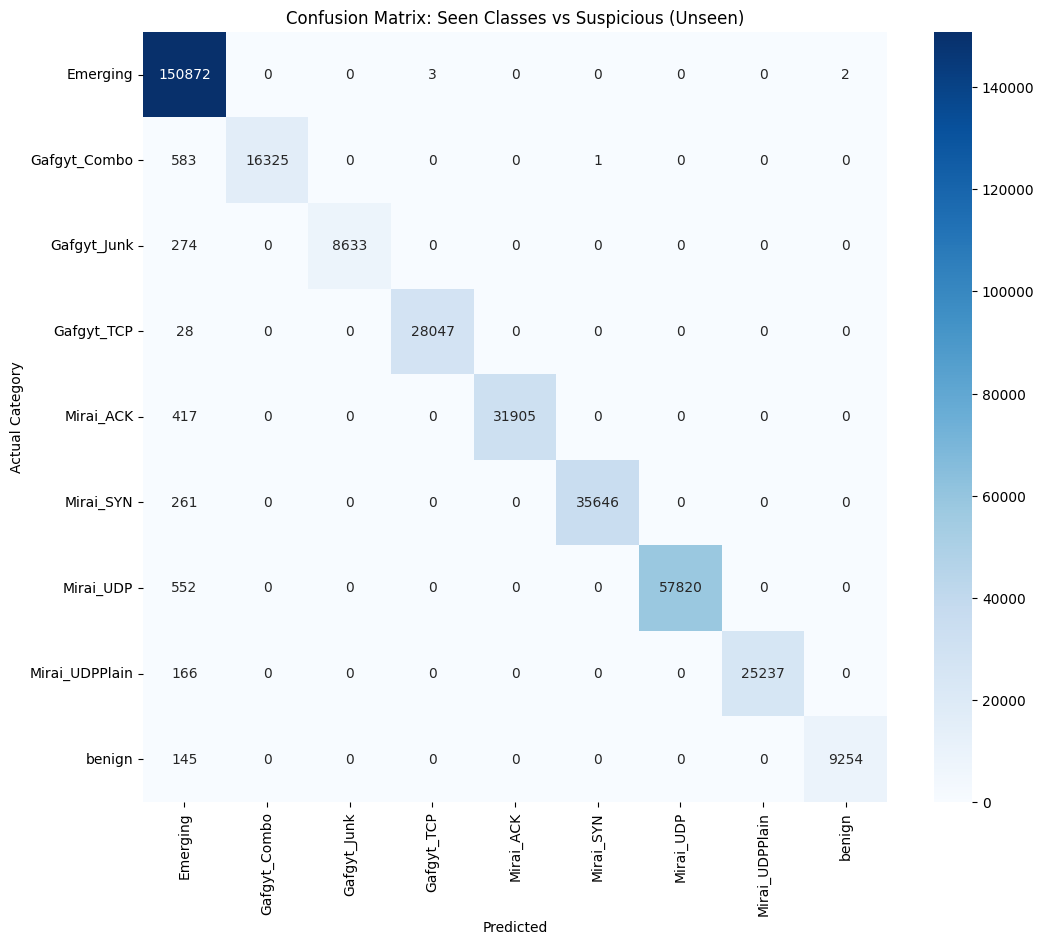


--- Detailed Analysis of Unseen Attack Detection ---


In [21]:

print("\nRunning Min–Max 3-way Inference on Mixed Test Set...")
y_pred = predict_minmax_3labels(model, test_loader, gate, le, device)
unique, counts = np.unique(y_pred, return_counts=True)
print(dict(zip(unique, counts)))

#%% [markdown]
# ## 8. Evaluation

y_true_mapped = []
for label in y_test_final_str:
    if label in UNSEEN_CLASSES:
        y_true_mapped.append('Emerging')
    else:
        y_true_mapped.append(label)

print("\nClassification Report:")
print(classification_report(y_true_mapped, y_pred))

# Confusion Matrix
plt.figure(figsize=(12, 10))
labels = sorted(list(set(y_true_mapped) | set(y_pred)))
cm = confusion_matrix(y_true_mapped, y_pred, labels=labels)

report_dict=report_dict = classification_report(
    y_true_mapped,
    y_pred,
    output_dict=True,
    zero_division=0
)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix: Seen Classes vs Suspicious (Unseen)")
plt.ylabel('Actual Category')
plt.xlabel('Predicted')
plt.savefig('confusion_matrix_ton_iot.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n--- Detailed Analysis of Unseen Attack Detection ---")
analysis_df = pd.DataFrame({
    'Actual_Category': y_test_final_str,
    'Prediction': y_pred
})

In [22]:
# for both the seen and unseen attacks


Running Inference on Mixed Test Set...

PART 1: PERFORMANCE ON SEEN CLASSES

Classification Report (Seen Classes):
                precision    recall  f1-score   support

      Emerging       0.00      0.00      0.00         0
  Gafgyt_Combo       1.00      0.97      0.98     16909
   Gafgyt_Junk       1.00      0.97      0.98      8907
    Gafgyt_TCP       1.00      1.00      1.00     28075
     Mirai_ACK       1.00      0.99      0.99     32322
     Mirai_SYN       1.00      0.99      1.00     35907
     Mirai_UDP       1.00      0.99      1.00     58372
Mirai_UDPPlain       1.00      0.99      1.00     25403
        benign       1.00      0.98      0.99      9399

      accuracy                           0.99    215294
     macro avg       0.89      0.88      0.88    215294
  weighted avg       1.00      0.99      0.99    215294



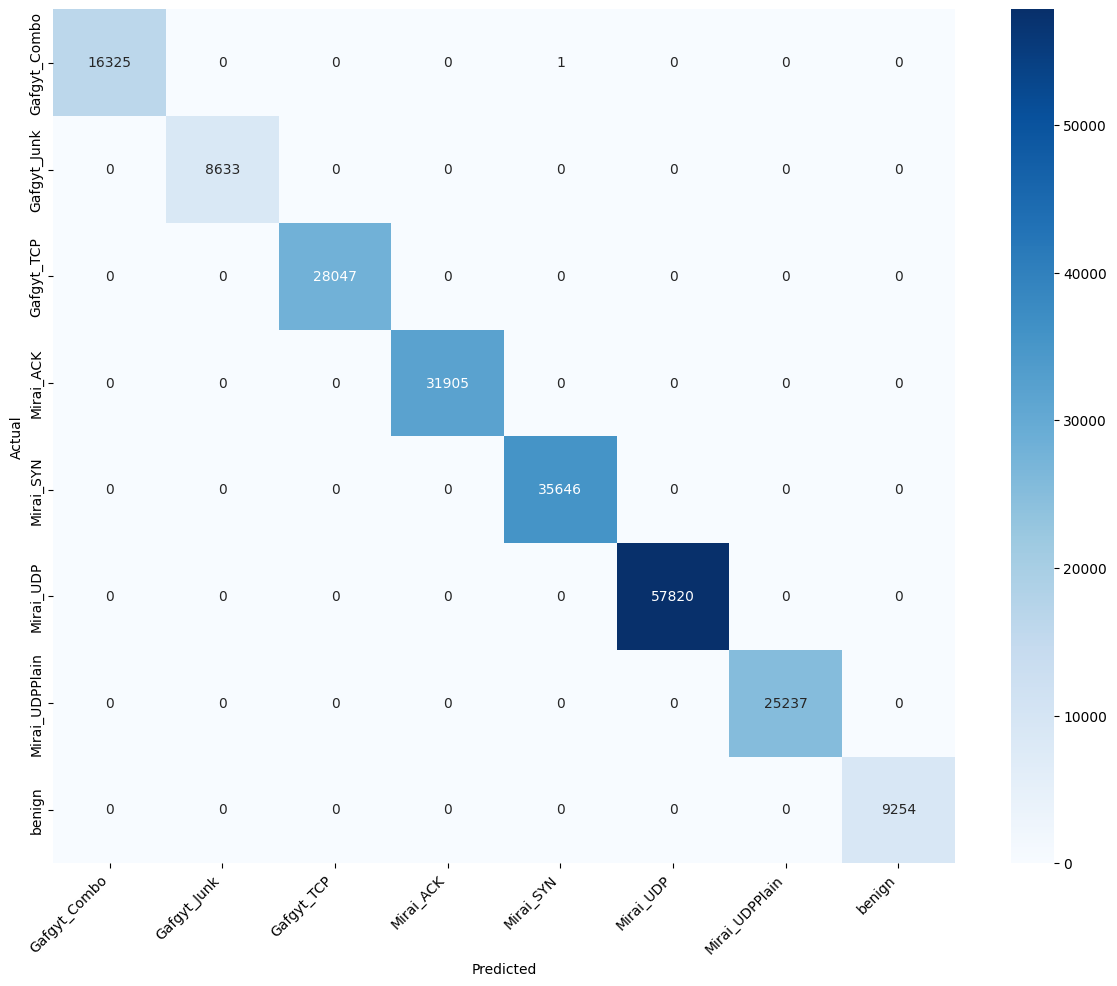


PART 2: DETECTION OF UNSEEN ATTACKS

Total Unseen Samples: 150877
Successfully Flagged as Emerging: 150872
Overall Detection Rate: 1.0000 (100.00%)

Detection Rate by Specific Unseen Attack:
Actual
Mirai_Scan    0.999967
Name: Predicted, dtype: float64


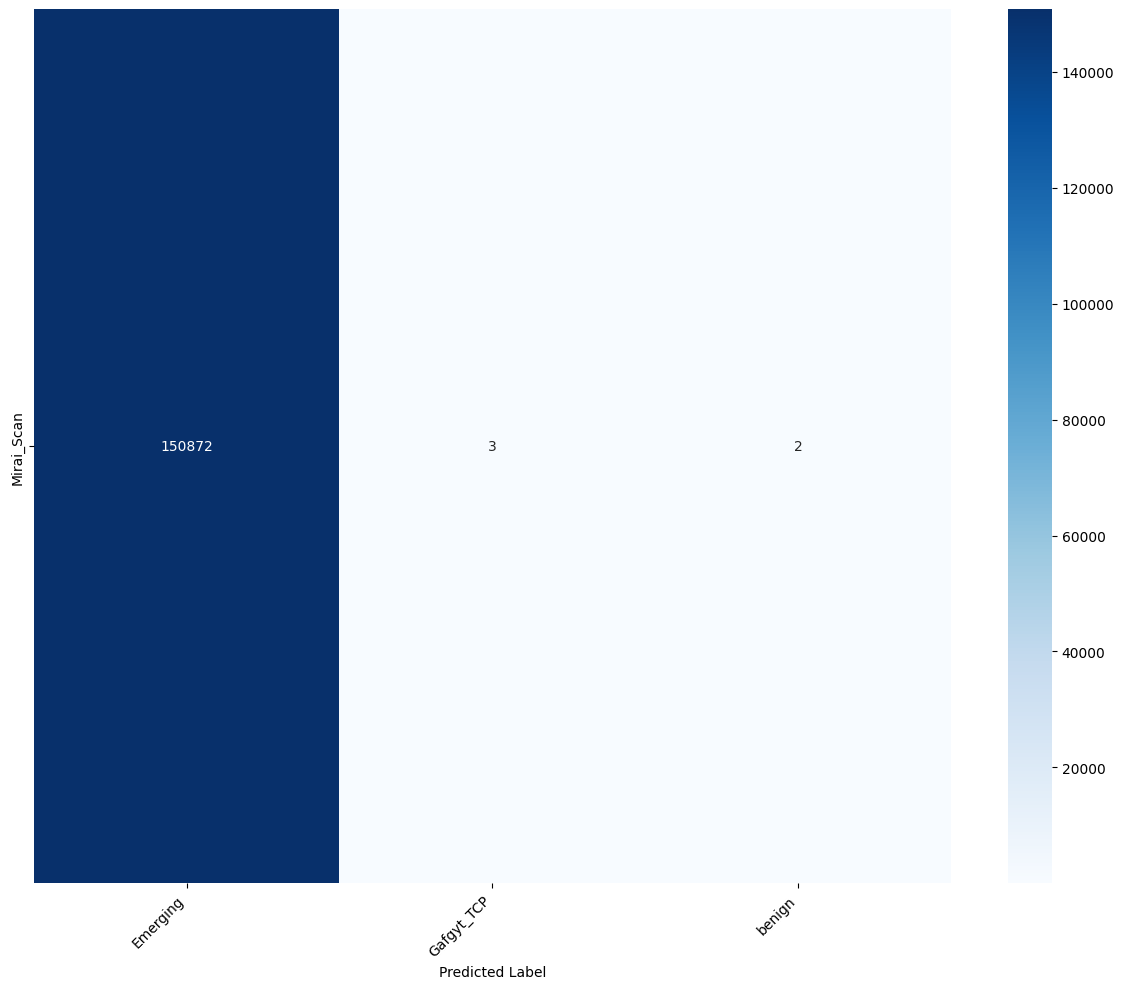

In [23]:

# --- 1. Run Inference ---
print("\nRunning Inference on Mixed Test Set...")
y_pred = predict_minmax_3labels(model, test_loader, gate, le, device)

# --- 2. Separate Data into 'Seen' vs 'Unseen' Groups ---
known_classes = set(le.classes_)

# Create mask
is_seen_mask = np.array([label in known_classes for label in y_test_final_str])

# Split
y_true_seen = np.array(y_test_final_str)[is_seen_mask]
y_pred_seen = y_pred[is_seen_mask]

y_true_unseen = np.array(y_test_final_str)[~is_seen_mask]
y_pred_unseen = y_pred[~is_seen_mask]

# ==========================================
# PART 1: SEEN CLASSES (Known Attacks)
# ==========================================
print("\n" + "="*50)
print("PART 1: PERFORMANCE ON SEEN CLASSES")
print("="*50)

if len(y_true_seen) > 0:
    print("\nClassification Report (Seen Classes):")
    # We calculate metrics normally
    print(classification_report(y_true_seen, y_pred_seen, zero_division=0))

    # --- CUSTOM MATRIX using crosstab ---
    # This is safer and easier to manipulate than confusion_matrix
    df_cm_seen = pd.crosstab(
        pd.Series(y_true_seen, name='Actual'),
        pd.Series(y_pred_seen, name='Predicted')
    )

    # USER REQUEST: Remove 'Emerging' column if it exists in Seen analysis
    if 'Emerging' in df_cm_seen.columns:
        df_cm_seen = df_cm_seen.drop(columns=['Emerging'])

    plt.figure(figsize=(12, 10))
    sns.heatmap(df_cm_seen, annot=True, fmt='d', cmap='Blues')
    plt.title("")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig("confusion_seen_baiot.png")
    plt.show()

else:
    print("No Seen samples in this test set.")

# ==========================================
# PART 2: UNSEEN ATTACKS (Unknowns)
# ==========================================
print("\n" + "="*50)
print("PART 2: DETECTION OF UNSEEN ATTACKS")
print("="*50)

if len(y_true_unseen) > 0:
    # 1. Detection Rate
    correctly_detected = np.sum(y_pred_unseen == 'Emerging')
    detection_rate = correctly_detected / len(y_true_unseen)
    
    print(f"\nTotal Unseen Samples: {len(y_true_unseen)}")
    print(f"Successfully Flagged as Emerging: {correctly_detected}")
    print(f"Overall Detection Rate: {detection_rate:.4f} ({detection_rate*100:.2f}%)")

    # 2. Detailed Breakdown (Fixing the groupby warning)
    # We select the 'Predicted' column strictly before applying logic
    analysis_df = pd.DataFrame({'Actual': y_true_unseen, 'Predicted': y_pred_unseen})
    
    print("\nDetection Rate by Specific Unseen Attack:")
    breakdown = analysis_df.groupby('Actual')['Predicted'].apply(
        lambda x: (x == 'Emerging').mean()
    )
    print(breakdown)

    # 3. Confusion Matrix via Crosstab (Fixes ValueError)
    # Rows = Actual Unseen Names, Cols = Predicted Labels
    df_cm_unseen = pd.crosstab(
        pd.Series(y_true_unseen, name=''),
        pd.Series(y_pred_unseen, name='Predicted Label')
    )

    # Reorder columns to put 'Emerging' first (for better visibility)
    cols = list(df_cm_unseen.columns)
    if 'Emerging' in cols:
        cols.remove('Emerging')
        cols.insert(0, 'Emerging')
        df_cm_unseen = df_cm_unseen[cols]

    plt.figure(figsize=(12, 10))
    sns.heatmap(df_cm_unseen, annot=True, fmt='d', cmap='Blues')
    plt.title("")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig("confusion_unseen_baiot.png")
    plt.show()

else:
    print("No Unseen samples in this test set.")

/tmp/ipykernel_55/1948428809.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


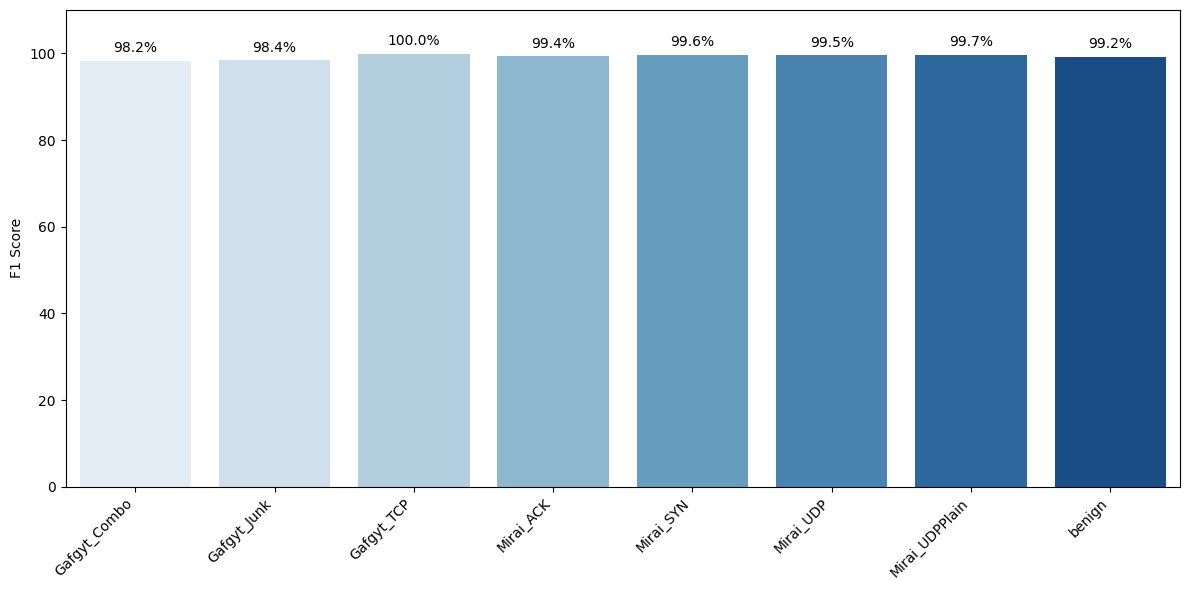

In [24]:


seen_report = classification_report(
    y_true_seen,
    y_pred_seen,
    output_dict=True,
    zero_division=0
)

# Keep only class rows (ignore averages) + EXCLUDE "Emerging"
seen_classes = [
    k for k in seen_report.keys()
    if k not in ['accuracy', 'macro avg', 'weighted avg', 'Emerging']
]

# Metric to show as % (recall)
seen_recall_pct = [seen_report[c]['f1-score'] * 100 for c in seen_classes]

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=seen_classes,
    y=seen_recall_pct,
    palette=sns.color_palette("Blues", n_colors=len(seen_classes))
)
plt.title("")
plt.ylabel("F1 Score")
plt.xlabel("")
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 110)  # headroom for labels

# Add % labels on top of bars
for p, val in zip(ax.patches, seen_recall_pct):
    ax.annotate(
        f"{val:.1f}%",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.tight_layout()
plt.savefig("seen_recall_bar_with_percent_no_emerging.png", dpi=300)
plt.show()

/tmp/ipykernel_55/888236440.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax_overall = sns.barplot(


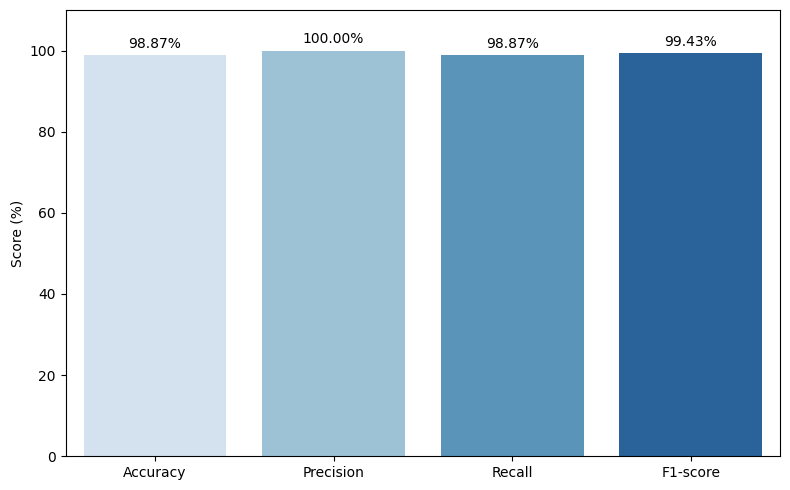

In [25]:
# ==========================================
# 4) Overall Metrics Visualization (Accuracy, Precision, Recall, F1)
# ==========================================
report_dict=seen_report
# Get overall metrics (use weighted avg for multi-class)
acc = report_dict["accuracy"] * 100
prec = report_dict["weighted avg"]["precision"] * 100
rec = report_dict["weighted avg"]["recall"] * 100
f1 = report_dict["weighted avg"]["f1-score"] * 100

overall_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score (%)": [acc, prec, rec, f1]
})

plt.figure(figsize=(8, 5))
ax_overall = sns.barplot(
    data=overall_df,
    x="Metric",
    y="Score (%)",
    palette=sns.color_palette("Blues", n_colors=len(overall_df))
)

plt.title("")
plt.ylabel("Score (%)")
plt.xlabel("")
plt.ylim(0, 110)

# Add values on top of bars
for container in ax_overall.containers:
    ax_overall.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig("overall_seen_metrics.png", dpi=300)
plt.show()


In [26]:
data["label"].value_counts()

NameError: name 'data' is not defined

In [ ]:
len(data.columns)

In [ ]:
data['type'].value_counts()

In [ ]:
plt.savefig("Confusion_matrix.png")

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve , auc
from itertools import cycle

In [ ]:
print("\n--- Generating ROC Curves ---")
# Filter test set to only include SEEN classes for valid ROC calculation
mask_seen = np.isin(y_test_final_str, SEEN_CLASSES)
y_test_seen_only = y_test_final_str[mask_seen]
X_test_seen_only = X_test_final[mask_seen] 

# Create a temporary loader
seen_ds = IoTDataset(X_test_seen_only, np.zeros(len(X_test_seen_only))) 
seen_loader = DataLoader(seen_ds, batch_size=CONFIG['batch_size'], shuffle=False)

# Get raw probabilities
probs_seen, _ = get_probabilities(model, seen_loader,'cuda') 

# Binarize labels
classes = list(le.classes_)
y_test_bin = label_binarize(y_test_seen_only, classes=classes)
n_classes = y_test_bin.shape[1]

# Plot
plt.figure(figsize=(10, 8))
fpr = dict()
tpr = dict()
roc_auc = dict()

# Calculate micro-average
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), probs_seen.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

plt.plot(fpr["micro"], tpr["micro"],
         label='Micro-average (AUC = {0:0.2f})'.format(roc_auc["micro"]),
         color='deeppink', linestyle=':', linewidth=4)

# Plot each class
colors = cycle(sns.color_palette("husl", n_classes)) # Distinct colors for lines
for i, color in zip(range(n_classes), colors):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], probs_seen[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='{0} (AUC = {1:0.2f})'.format(classes[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Multiclass ROC Curve', fontsize=16)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.savefig('/kaggle/working/multiclass_roc_curve.png', dpi=300)
plt.show()

print("\nAll charts generated and saved.")

**new explainable ai**

In [ ]:
model.eval()

In [27]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import shap
import lime
from lime import lime_tabular
# import dice_ml
import matplotlib.pyplot as plt

In [28]:
def predict_proba_wrapper(data_2d):
    """
    Input:  (N, Features) 2D numpy array or DataFrame
    Output: (N, Classes) 2D numpy array of probabilities
    """
    # 1. Handle DataFrame input (DiCE sends DataFrames)
    if isinstance(data_2d, pd.DataFrame):
        data_2d = data_2d.values.astype(np.float32)
    else:
        data_2d = np.array(data_2d, dtype=np.float32)
        
    # 2. Reshape to (Batch, Features, 1) as expected by your load_and_process logic
    data_3d = data_2d.reshape(data_2d.shape[0], data_2d.shape[1], 1)
    
    # 3. Predict
    tensor_data = torch.tensor(data_3d).to(device)
    with torch.no_grad():
        logits = model(tensor_data)
        probs = torch.nn.functional.softmax(logits, dim=1)
        
    return probs.cpu().numpy()

# Prepare 2D data for XAI tools (Flatten the 3rd dimension)
X_train_2d = X_train.reshape(X_train.shape[0], -1)
X_test_2d = X_test_final.reshape(X_test_final.shape[0], -1)
feature_names = [f"Feature_{i}" for i in range(X_train_2d.shape[1])]
class_names = le.classes_ # From your LabelEncoder

In [29]:
class SklearnModelWrapper:
    def __init__(self, model, device):
        self.model = model
        self.device = device

    def predict_proba(self, data_2d):
        """
        Handles 2D input, reshapes to 3D, runs on CPU in batches to avoid OOM.
        """
        # 1. Handle Input Type
        if isinstance(data_2d, pd.DataFrame):
            data_2d = data_2d.values.astype(np.float32)
        else:
            data_2d = np.array(data_2d, dtype=np.float32)
            
        # 2. Reshape for CNN/LSTM: (N, Features) -> (N, Features, 1)
        data_3d = data_2d.reshape(data_2d.shape[0], data_2d.shape[1], 1)
        
        # 3. Run in Mini-Batches (CPU)
        batch_size = 64
        all_probs = []
        
        # Ensure model is on CPU for this process
        self.model.to(self.device)
        self.model.eval()
        
        with torch.no_grad():
            for i in range(0, len(data_3d), batch_size):
                batch_np = data_3d[i : i + batch_size]
                batch_tensor = torch.tensor(batch_np).to(self.device)
                
                logits = self.model(batch_tensor)
                probs = torch.nn.functional.softmax(logits, dim=1)
                all_probs.append(probs.cpu().numpy())

        return np.vstack(all_probs)

    def predict(self, data_2d):
        """Helper for DiCE which sometimes asks for hard labels"""
        probs = self.predict_proba(data_2d)
        return np.argmax(probs, axis=1)

# Initialize the Wrapper on CPU
device_xai = torch.device("cuda")
model_wrapper = SklearnModelWrapper(model, device_xai)
print("\n--- Generating SHAP (Global Importance) ---")
# Use K-Means to summarize background data (Speed up)
background_data = shap.kmeans(X_train_2d, 20) 


--- Generating SHAP (Global Importance) ---


**Lime Charts**

Features: 115 | Classes: 8

Building SHAP background...
Creating KernelExplainer (LOGITS)...
Predicted: Gafgyt_Combo | Prob: 0.86841875
Computing SHAP values for 1 sample...


  0%|          | 0/1 [00:00<?, ?it/s]

x features: 115 | shap vals: 115 | feature_names: 115


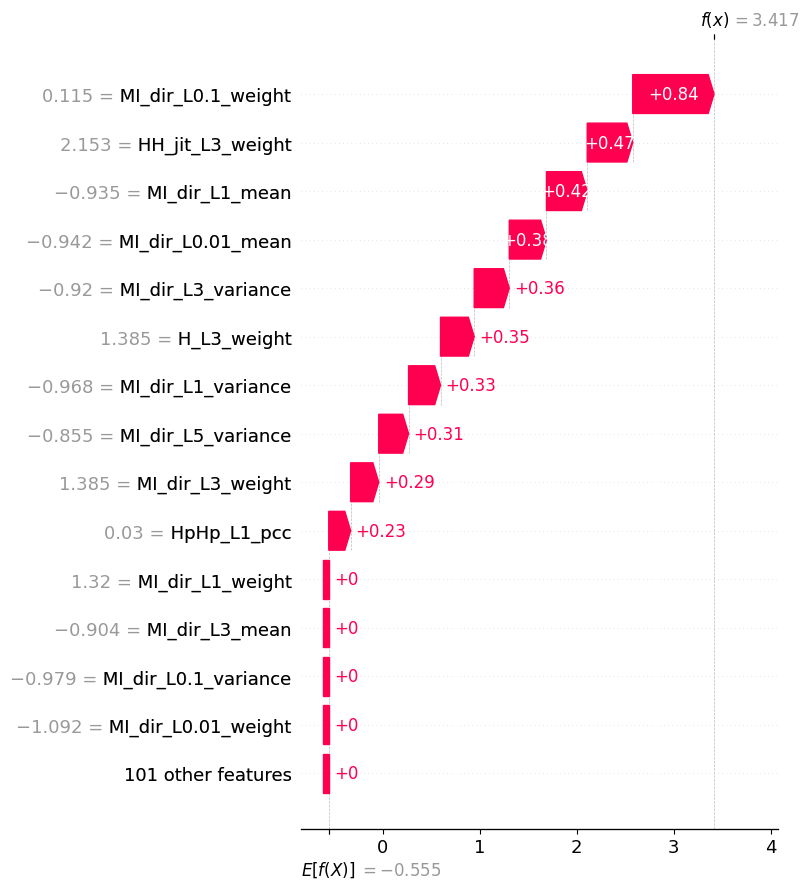


Generating LIME explanation...


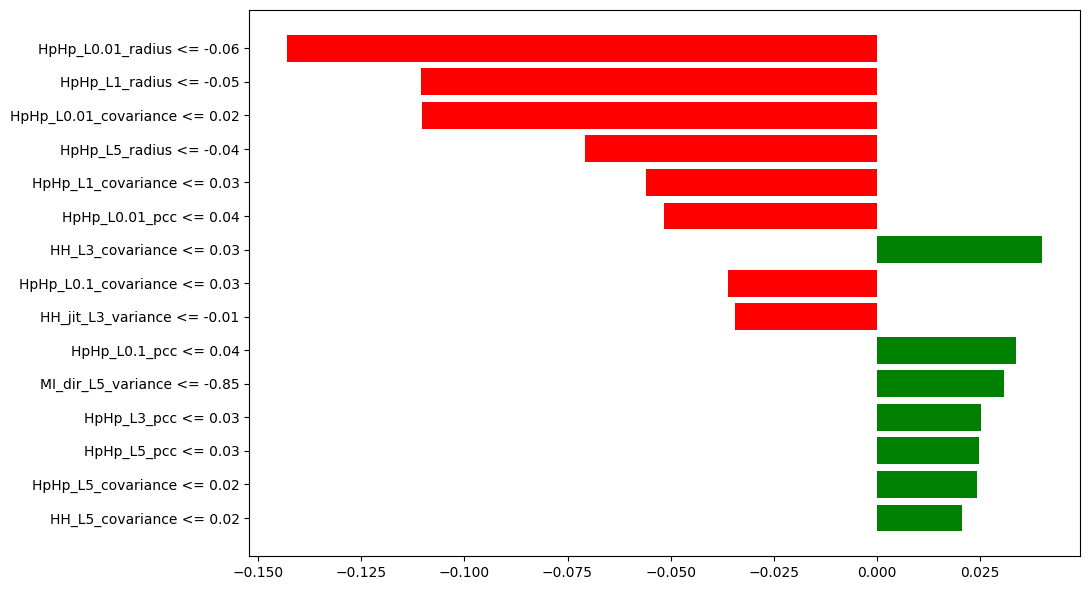


Top LIME features:
HpHp_L0.01_radius <= -0.06                    -0.1429
HpHp_L1_radius <= -0.05                       -0.1106
HpHp_L0.01_covariance <= 0.02                 -0.1103
HpHp_L5_radius <= -0.04                       -0.0707
HpHp_L1_covariance <= 0.03                    -0.0560
HpHp_L0.01_pcc <= 0.04                        -0.0515
HH_L3_covariance <= 0.03                      +0.0400
HpHp_L0.1_covariance <= 0.03                  -0.0362
HH_jit_L3_variance <= -0.01                   -0.0345
HpHp_L0.1_pcc <= 0.04                         +0.0336
MI_dir_L5_variance <= -0.85                   +0.0308
HpHp_L3_pcc <= 0.03                           +0.0251
HpHp_L5_pcc <= 0.03                           +0.0246
HpHp_L5_covariance <= 0.02                    +0.0243
HH_L5_covariance <= 0.02                      +0.0207


In [43]:
# ============================================================
# XAI BLOCK: SHAP Waterfall (LOGITS) + LIME chart (multi-class)
# Paste AFTER model is loaded and you have X_train, X_test_final, full_data, le
# ============================================================

import numpy as np
import pandas as pd
import torch
import shap
import matplotlib.pyplot as plt
from lime.lime_tabular import LimeTabularExplainer

# -----------------------------
# 1) Prepare 2D data
# -----------------------------
X_train_2d = X_train.reshape(X_train.shape[0], -1).astype(np.float32)          # (N, 115)
X_test_2d  = X_test_final.reshape(X_test_final.shape[0], -1).astype(np.float32)

feature_names_real = list(full_data.drop(['label'], axis=1).columns)           # 115 names
class_names = le.classes_

assert X_train_2d.shape[1] == len(feature_names_real), "Feature name mismatch!"
print("Features:", X_train_2d.shape[1], "| Classes:", len(class_names))


# -----------------------------
# 2) Wrapper: LOGITS (best for waterfall)
# -----------------------------
device_xai = device  # uses your CUDA/CPU device

def predict_logits_np(data_2d):
    """
    Input: (N, F) numpy or DataFrame
    Output: (N, C) logits numpy
    """
    if isinstance(data_2d, pd.DataFrame):
        data_2d = data_2d.values.astype(np.float32)
    else:
        data_2d = np.array(data_2d, dtype=np.float32)

    data_3d = data_2d.reshape(data_2d.shape[0], data_2d.shape[1], 1)  # (N,115,1)
    x = torch.tensor(data_3d, dtype=torch.float32, device=device_xai)

    model.eval()
    with torch.no_grad():
        logits = model(x)  # (N,C)

    return logits.detach().cpu().numpy()


def predict_proba_np(data_2d):
    """
    Input: (N,F)
    Output: (N,C) probabilities numpy (for LIME)
    """
    logits = predict_logits_np(data_2d)
    exps = np.exp(logits - logits.max(axis=1, keepdims=True))
    return exps / exps.sum(axis=1, keepdims=True)


# -----------------------------
# 3) SHAP Waterfall helper (robust for multiclass shapes)
# -----------------------------
def get_shap_vector_for_class(shap_out, class_idx, sample_row=0):
    """
    KernelExplainer may return:
    - list of arrays: [class] -> (n, f)
    - array (n, f, c)
    - array (n, f)
    This returns (f,) for the chosen class.
    """
    if isinstance(shap_out, list):
        return np.asarray(shap_out[class_idx])[sample_row, :]
    arr = np.asarray(shap_out)
    if arr.ndim == 2:
        return arr[sample_row, :]
    if arr.ndim == 3:
        return arr[sample_row, :, class_idx]
    raise ValueError(f"Unsupported SHAP shape: {arr.shape}")

def get_expected_value_for_class(expected_value, class_idx):
    if isinstance(expected_value, (list, np.ndarray)):
        return expected_value[class_idx]
    return expected_value


# -----------------------------
# 4) Build SHAP KernelExplainer (use small KMeans background)
# -----------------------------
print("\nBuilding SHAP background...")
background = shap.kmeans(X_train_2d, 20)  # good speed/quality tradeoff

print("Creating KernelExplainer (LOGITS)...")
explainer = shap.KernelExplainer(predict_logits_np, background)

# -----------------------------
# 5) Pick a sample & compute SHAP
# -----------------------------
sample_idx = 0  # <-- change
x1 = X_test_2d[sample_idx].reshape(1, -1)

# predicted class (based on probability)
probs = predict_proba_np(x1)[0]
pred_class_idx = int(np.argmax(probs))
print("Predicted:", class_names[pred_class_idx], "| Prob:", probs[pred_class_idx])

print("Computing SHAP values for 1 sample...")
shap_out = explainer.shap_values(x1, nsamples=800)  # increase if you want smoother (slower)

vals = get_shap_vector_for_class(shap_out, pred_class_idx, sample_row=0)       # (115,)
base_val = get_expected_value_for_class(explainer.expected_value, pred_class_idx)

# sanity check
print("x features:", x1.shape[1], "| shap vals:", vals.shape[0], "| feature_names:", len(feature_names_real))
assert x1.shape[1] == vals.shape[0] == len(feature_names_real)

# -----------------------------
# 6) SHAP Waterfall plot (visible bars because LOGITS)
# -----------------------------
exp = shap.Explanation(
    values=vals,
    base_values=base_val,
    data=x1[0],
    feature_names=feature_names_real
)

plt.figure(figsize=(11, 7))
shap.plots.waterfall(exp, max_display=15, show=False)
plt.title(f"", fontsize=14)
plt.tight_layout()
plt.savefig(f"shap_waterfall_logits_sample{sample_idx}_{class_names[pred_class_idx]}.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 7) LIME Explanation chart (uses probabilities)
# ============================================================
print("\nGenerating LIME explanation...")
lime_explainer = LimeTabularExplainer(
    training_data=X_train_2d,
    feature_names=feature_names_real,
    class_names=[str(c) for c in class_names],
    mode="classification",
    discretize_continuous=True
)

lime_exp = lime_explainer.explain_instance(
    data_row=X_test_2d[sample_idx],
    predict_fn=predict_proba_np,
    num_features=15,
    top_labels=1
)

fig = lime_exp.as_pyplot_figure(label=pred_class_idx)
fig.set_size_inches(11, 6)
plt.title(f"", fontsize=14)
plt.tight_layout()
plt.savefig(f"lime_explanation_sample{sample_idx}_{class_names[pred_class_idx]}.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nTop LIME features:")
for feat, w in lime_exp.as_list(label=pred_class_idx):
    print(f"{feat:45s} {w:+.4f}")

Loaded 115 feature names.
Generating SHAP Summary Plot...


  0%|          | 0/20 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 8 iterations, i.e. alpha=3.101e-02, with an active set of 8 regressors, and the smallest cholesky pivot element being 8.429e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 1 iterations, i.e. alpha=7.482e-03, with an active set of 1 regressors, and the smallest cholesky pivot element being 5.960e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 2 iterations, i.e. alpha=2.427e-03, with an active set of 2 regressors, and the smallest cholesky pivot element being 4

<Figure size 1200x800 with 0 Axes>

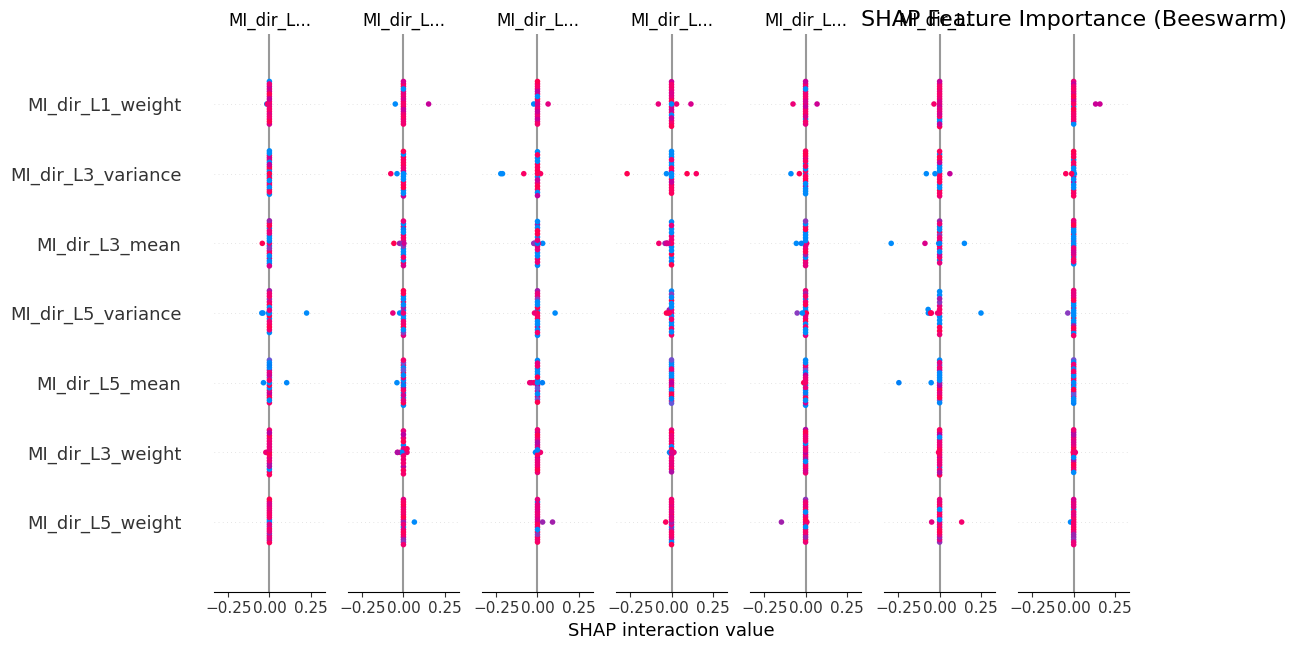

/tmp/ipykernel_55/2690866819.py:37: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


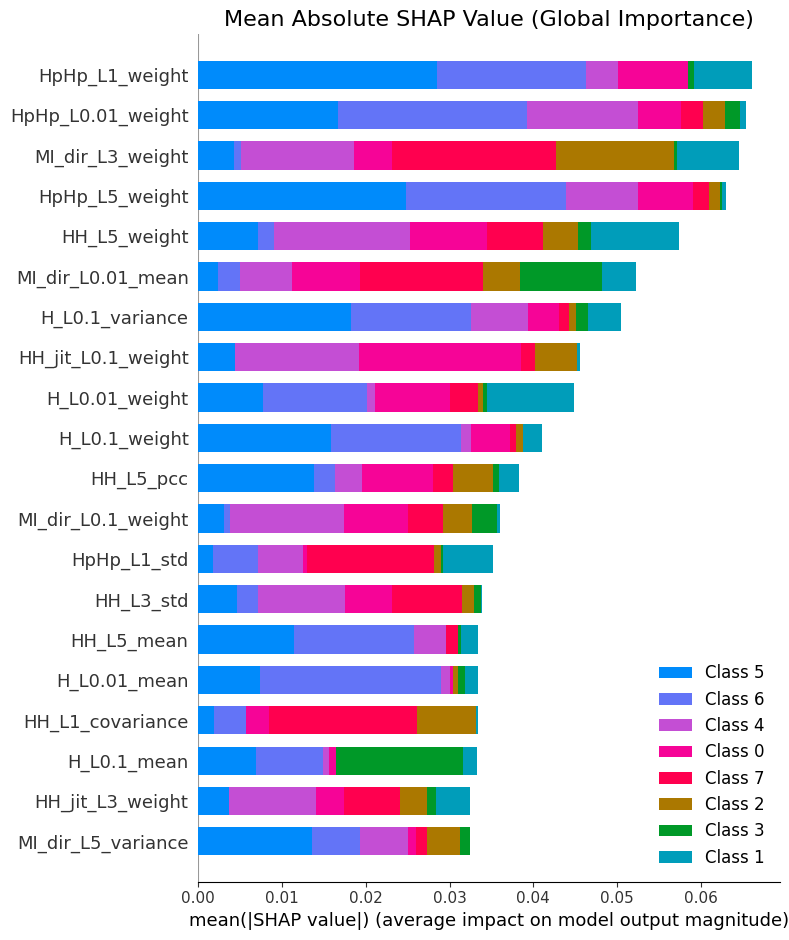

In [37]:
import shap
import matplotlib.pyplot as plt

# --- 1. Get Real Feature Names ---
# We need to grab the column names from your original dataframe before scaling
# Assuming 'full_data' is your pandas DataFrame from the load_and_process function
feature_names_real = list(full_data.drop(['label'], axis=1).columns)

print(f"Loaded {len(feature_names_real)} feature names.")

# --- 2. Generate the SHAP Summary Plot (Beeswarm) ---
print("Generating SHAP Summary Plot...")

# Calculate SHAP values (using the CPU-safe wrapper from before)
# We use more samples (nsamples=100) for a denser, better-looking plot

# Initialize Explainer
explainer_shap = shap.KernelExplainer(model_wrapper.predict_proba, background_data)

shap_values = explainer_shap.shap_values(X_test_2d[:20], nsamples=100)

# Create the plot
plt.figure(figsize=(12, 8)) # Make it big enough to read
shap.summary_plot(
    shap_values, 
    X_test_2d[:20], 
    feature_names=feature_names_real, # <--- KEY FIX: Use real names
    show=False
)
plt.title("SHAP Feature Importance (Beeswarm)", fontsize=16)
plt.tight_layout()
plt.show()

# --- 3. Generate a Bar Plot (Simpler View) ---
# Sometimes a simple bar chart is easier to read than the beeswarm
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values, 
    X_test_2d[:20], 
    feature_names=feature_names_real, 
    plot_type="bar", # <--- Changes to bar chart
    show=False
)
plt.title("Mean Absolute SHAP Value (Global Importance)", fontsize=16)
plt.tight_layout()
plt.show()

Loaded 115 feature names.
Initializing KernelExplainer...
Computing SHAP values...


  0%|          | 0/20 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 1 iterations, i.e. alpha=1.182e-02, with an active set of 1 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
/tmp/ipykernel_55/1876814771.py:25: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
/usr/local/lib/python3.12/dist-packages/shap/plots/

<Figure size 1200x800 with 0 Axes>

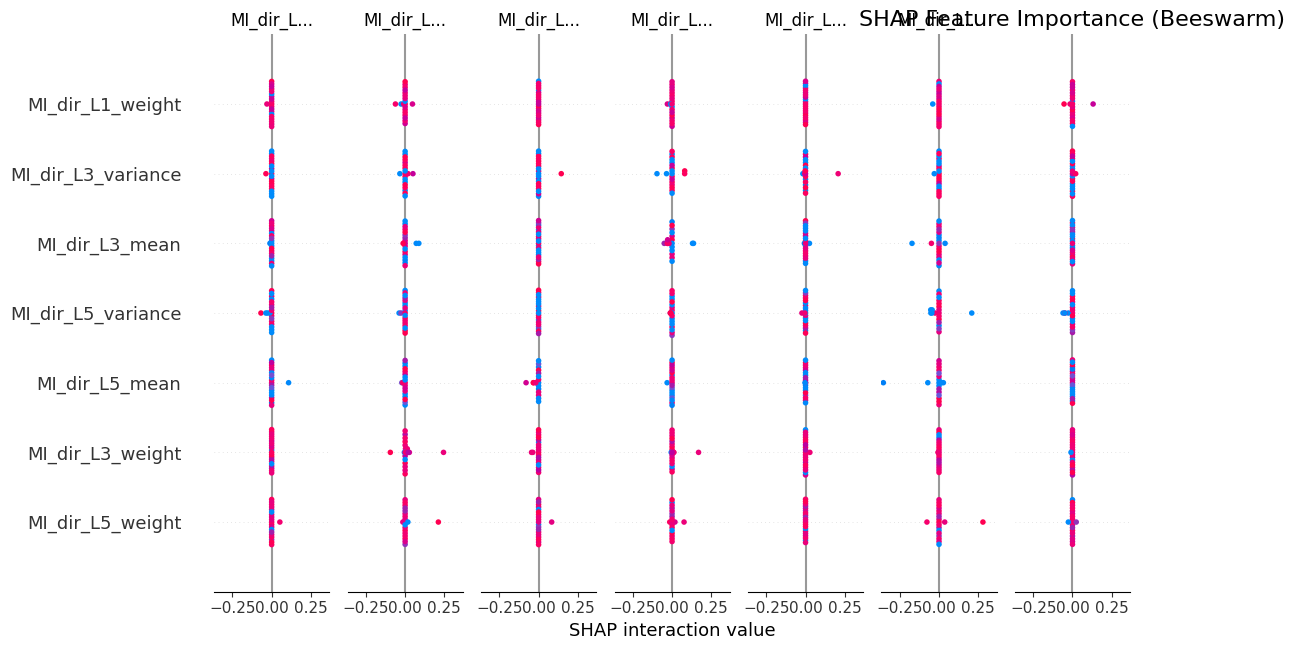

/tmp/ipykernel_55/1876814771.py:39: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


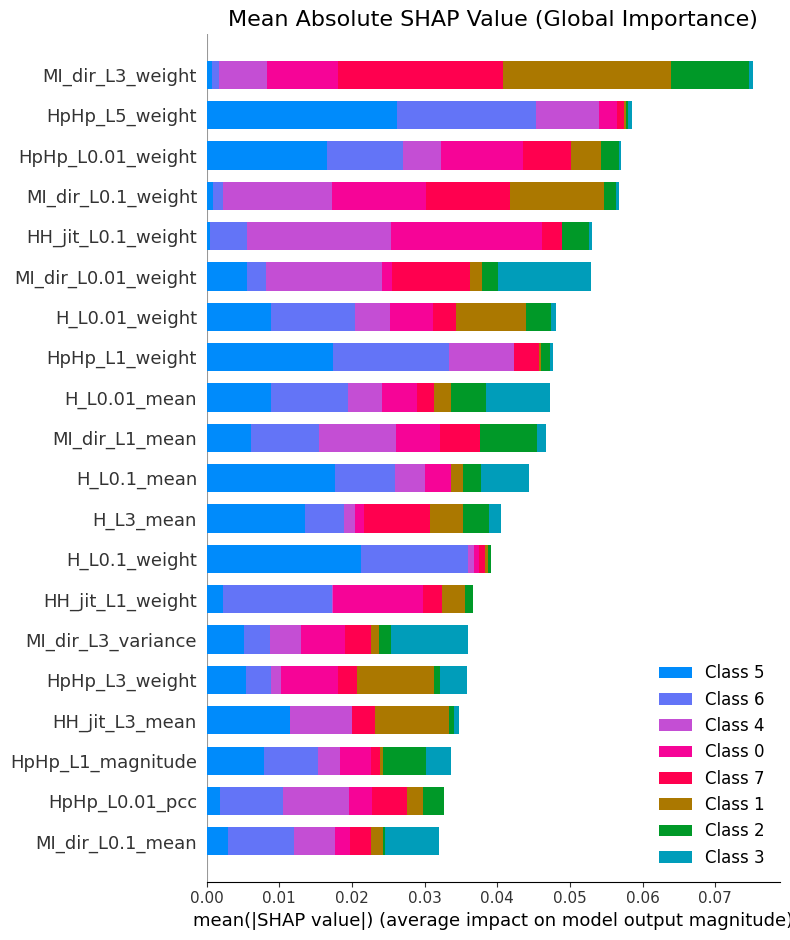

Generating Decision Plot...


ValueError: The feature_names arg must include all features represented in shap_values.

<Figure size 1200x600 with 0 Axes>

In [40]:
import shap
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Get Real Feature Names ---
feature_names_real = list(full_data.drop(['label'], axis=1).columns)
print(f"Loaded {len(feature_names_real)} feature names.")

# --- 2. Initialize SHAP Kernel Explainer ---
print("Initializing KernelExplainer...")
explainer_shap = shap.KernelExplainer(
    model_wrapper.predict_proba,
    background_data
)

# Compute SHAP values
X_explain = X_test_2d[:20]
print("Computing SHAP values...")
shap_values = explainer_shap.shap_values(X_explain, nsamples=100)

# =========================================================
# 3) SHAP Beeswarm Plot
# =========================================================
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=feature_names_real,
    show=False
)
plt.title("SHAP Feature Importance (Beeswarm)", fontsize=16)
plt.tight_layout()
plt.show()

# =========================================================
# 4) SHAP Global Bar Plot
# =========================================================
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=feature_names_real,
    plot_type="bar",
    show=False
)
plt.title("Mean Absolute SHAP Value (Global Importance)", fontsize=16)
plt.tight_layout()
plt.show()

# =========================================================
# 5) SHAP Decision Plot (NEW)
# =========================================================

print("Generating Decision Plot...")

# Pick class to visualize
class_idx = 0  # change if needed

# Expected value for chosen class
expected_value = explainer_shap.expected_value[class_idx]

# SHAP values for that class
sv_class = shap_values[class_idx]

# Choose sample index
sample_idx = 0

plt.figure(figsize=(12, 6))
shap.decision_plot(
    expected_value,
    sv_class[sample_idx],
    X_explain[sample_idx],
    feature_names=feature_names_real,
    show=False
)
plt.title(f"SHAP Decision Plot (Class {class_idx}, Sample {sample_idx})")
plt.tight_layout()
plt.show()


In [41]:
import shap
import matplotlib.pyplot as plt

# --- 1. Define Correct Class Names ---
# These must be sorted alphabetically to match how the model outputs them
SEEN_CLASSES = ['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP', 
                'Gafgyt_Combo', 'benign', 'Gafgyt_Junk', 'Mirai_UDPPlain']
class_names_model = sorted(SEEN_CLASSES)

Loaded 115 feature names.
Calculating SHAP values (using CPU wrapper)...


  0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/shap/explainers/_kernel.py:708: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up the L1 regularization with num_features(N) where N is less than the number of samples,
3) group features together to reduce the number of inputs that need to be explained.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 3 iterations, i.e. alpha=3.572e-03, with an active set of 3 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 

Generating Beeswarm Plot...


/tmp/ipykernel_55/2018765454.py:23: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:743: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:743: FutureWarning: The NumPy glo

<Figure size 1500x1000 with 0 Axes>

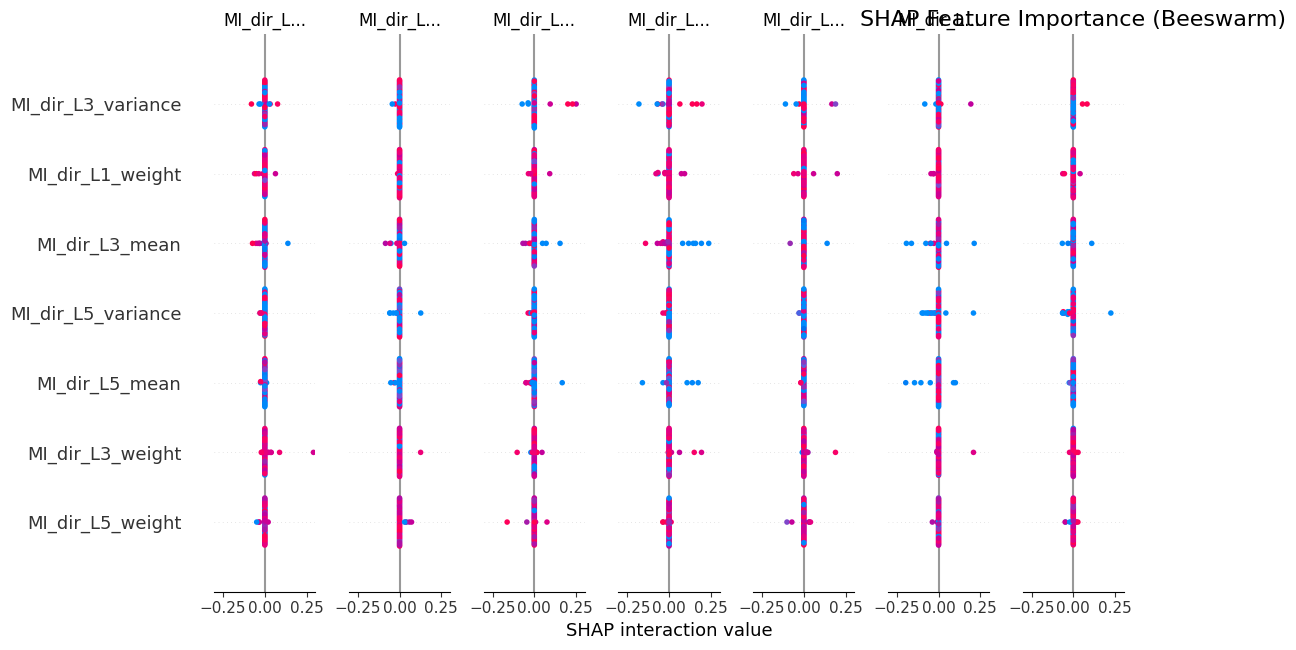

Generating Bar Plot...


/tmp/ipykernel_55/2018765454.py:37: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


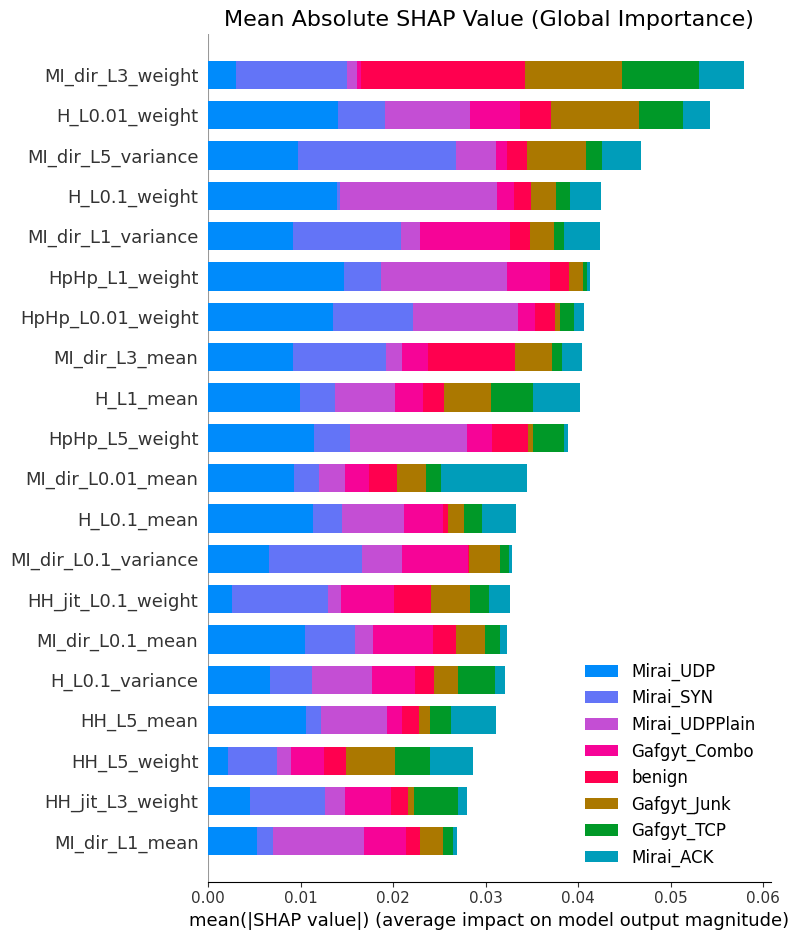

In [42]:


# --- 2. Get Real Feature Names ---
# Assuming 'full_data' is loaded. If not, we fall back to generic names.
try:
    feature_names_real = list(full_data.drop(['label'], axis=1).columns)
except:
    feature_names_real = [f"Feature_{i}" for i in range(115)]

print(f"Loaded {len(feature_names_real)} feature names.")

# --- 3. Calculate SHAP Values ---
print("Calculating SHAP values (using CPU wrapper)...")
# Ensure 'explainer_shap' and 'X_test_2d' are defined from previous steps
# We use 50 samples for a better-looking plot

# Initialize Explainer
explainer_shap = shap.KernelExplainer(model_wrapper.predict_proba, background_data)

shap_values = explainer_shap.shap_values(X_test_2d[:50], nsamples=100)

# --- 4. Generate SHAP Summary Plot (Beeswarm) ---
print("Generating Beeswarm Plot...")
plt.figure(figsize=(15, 10))
shap.summary_plot(
    shap_values, 
    X_test_2d[:50], 
    feature_names=feature_names_real, 
    class_names=class_names_model,  # <--- ADDED: Shows specific attack names
    show=False
)
plt.title("SHAP Feature Importance (Beeswarm)", fontsize=16)
plt.tight_layout()
plt.show()

# --- 5. Generate Bar Plot (Global Importance) ---
print("Generating Bar Plot...")
plt.figure(figsize=(15, 10))
shap.summary_plot(
    shap_values, 
    X_test_2d[:50], 
    feature_names=feature_names_real, 
    class_names=class_names_model,  # <--- ADDED: Shows specific attack names
    plot_type="bar", 
    show=False
)
plt.title("Mean Absolute SHAP Value (Global Importance)", fontsize=16)
plt.tight_layout()
plt.show()

Generating Bar Plot...


/tmp/ipykernel_55/2401821106.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


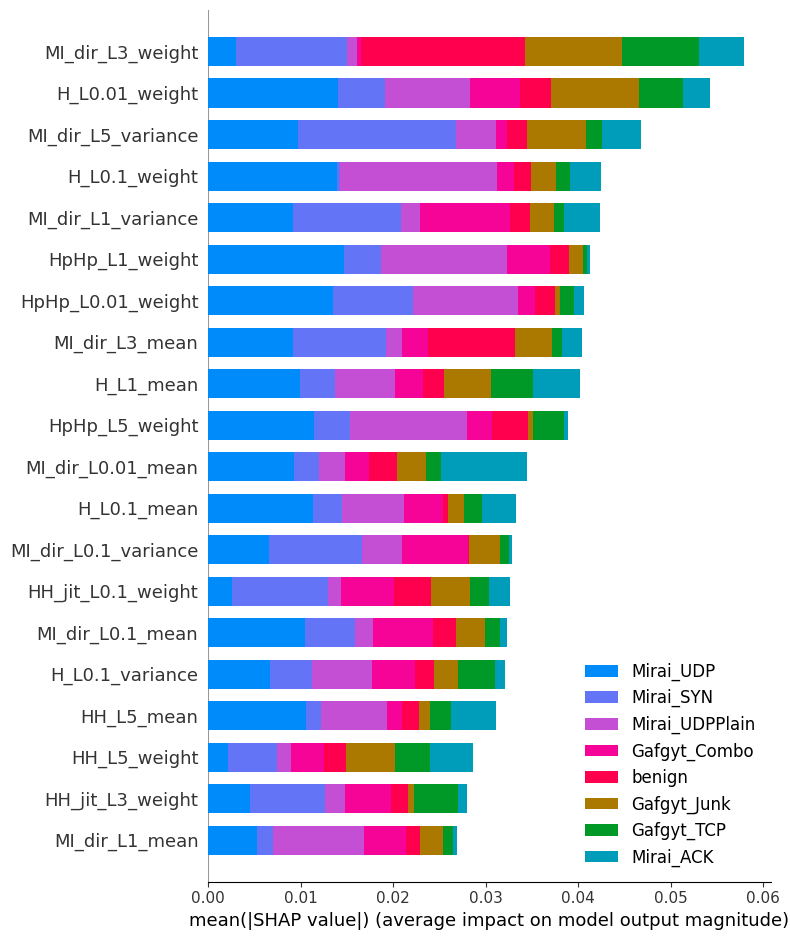

In [43]:
print("Generating Bar Plot...")
plt.figure(figsize=(15, 10))
shap.summary_plot(
    shap_values, 
    X_test_2d[:50], 
    feature_names=feature_names_real, 
    class_names=class_names_model,  # <--- ADDED: Shows specific attack names
    plot_type="bar", 
    show=False
)
plt.title("", fontsize=16)
plt.tight_layout()
plt.savefig("Shap_Summary_Plots.png")
plt.show()

In [49]:
print("SHAP shape:", sv_class.shape)
print("Feature names:", len(feature_names_real))


SHAP shape: (50, 115, 8)
Feature names: 115


Generating SHAP Decision Plot...
Predicted class: 0


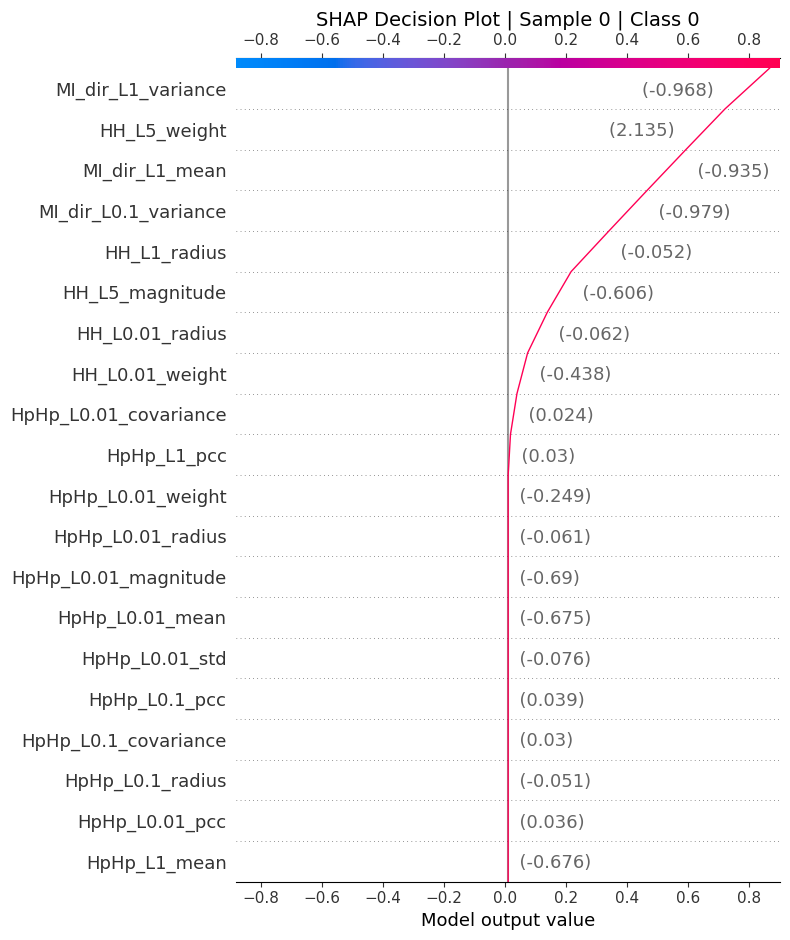

In [50]:
print("Generating SHAP Decision Plot...")

sample_idx = 0

# Predict class
sample_probs = model_wrapper.predict_proba(
    X_explain[sample_idx:sample_idx+1]
)[0]
pred_class = int(np.argmax(sample_probs))

print("Predicted class:", pred_class)

# SHAP format: (samples, features, classes)
# Select predicted class
sv_class = shap_values[:, :, pred_class]

expected_value = explainer_shap.expected_value[pred_class]

plt.figure(figsize=(12, 6))

shap.decision_plot(
    expected_value,
    sv_class[sample_idx],          # shape (features,)
    X_explain[sample_idx],
    feature_names=feature_names_real,
    show=False
)

plt.title(
    f"SHAP Decision Plot | Sample {sample_idx} | Class {pred_class}",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    f"shap_decision_plot_sample_{sample_idx}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


In [48]:
# =========================================================
# 5) SHAP Decision Plot (Fixed)
# =========================================================

print("Generating SHAP Decision Plot...")

sample_idx = 0

# Predict class
sample_probs = model_wrapper.predict_proba(
    X_explain[sample_idx:sample_idx+1]
)[0]
pred_class = int(np.argmax(sample_probs))

# Handle multi-class outputs
if isinstance(shap_values, list):
    sv_class = shap_values[pred_class]
    expected_value = explainer_shap.expected_value[pred_class]
else:
    sv_class = shap_values
    expected_value = explainer_shap.expected_value

# ---- Fix feature mismatch ----
num_features = sv_class.shape[1]
feature_names_fixed = feature_names_real[:num_features]
X_sample_fixed = X_explain[sample_idx][:num_features]

plt.figure(figsize=(12, 6))

shap.decision_plot(
    expected_value,
    sv_class[sample_idx][:num_features],
    X_sample_fixed,
    feature_names=feature_names_fixed,
    show=False
)

plt.title(
    f"SHAP Decision Plot | Sample {sample_idx} | Class {pred_class}",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    f"shap_decision_plot_sample_{sample_idx}.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()


Generating SHAP Decision Plot...


ValueError: The feature_names arg must include all features represented in shap_values.

<Figure size 1200x600 with 0 Axes>

In [ ]:
import dice_ml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Configuration (Fixes NameError) ---
idx_to_explain = 0  # <--- FIXED: Defined explicitly here
target_class_name = 'benign' # The class we want to reach

print(f"Generating Counterfactual for Sample {idx_to_explain}...")

# --- 2. Setup Wrapper Class ---
# DiCE requires a class with .predict_proba(), not just a function.
class SklearnModelWrapper:
    def __init__(self, prediction_function):
        self.prediction_function = prediction_function
        
    def predict_proba(self, instances):
        return self.prediction_function(instances)
        
    def predict(self, instances):
        # DiCE sometimes asks for strict class labels
        probs = self.prediction_function(instances)
        return np.argmax(probs, axis=1)

# Initialize the wrapper with your CPU-safe function
# (Assumes 'predict_proba_wrapper_safe' is defined from previous steps)
model_dice = SklearnModelWrapper(predict_proba_wrapper)

# --- 3. Setup DiCE Data & Model ---
# Create DataFrame with labels for training data
df_train_dice = pd.DataFrame(X_train_2d, columns=feature_names_real)
df_train_dice['label'] = y_train 

d = dice_ml.Data(
    dataframe=df_train_dice, 
    continuous_features=feature_names_real, 
    outcome_name='label'
)

m = dice_ml.Model(model=model_dice, backend="sklearn")

# --- 4. Generate Counterfactual ---
exp_dice = dice_ml.Dice(d, m, method="random")

# Find the numeric index for 'benign'
if target_class_name in class_names_model:
    target_idx = class_names_model.index(target_class_name)
else:
    print(f"Warning: '{target_class_name}' not found in classes. Defaulting to index 0.")
    target_idx = 0

# Prepare the query instance
query_instance = pd.DataFrame([X_test_2d[idx_to_explain]], columns=feature_names_real)

# Generate
dice_result = exp_dice.generate_counterfactuals(
    query_instance, 
    total_CFs=1, 
    desired_class=target_idx
)

# --- 5. Visualize & Save ---
cf_df = dice_result.cf_examples_list[0].final_cfs_df

if not cf_df.empty:
    # Calculate difference between Original and Counterfactual
    original_vals = query_instance.iloc[0].values
    cf_vals = cf_df.iloc[0][feature_names_real].values
    diff = cf_vals - original_vals
    
    # Filter for significant changes
    changed_indices = np.where(np.abs(diff) > 1e-4)[0]
    
    if len(changed_indices) > 0:
        plt.figure(figsize=(10, 6))
        
        # Get data for plotting
        feats = [feature_names_real[i] for i in changed_indices]
        vals = diff[changed_indices]
        colors = ['green' if x > 0 else 'red' for x in vals]
        
        plt.bar(feats, vals, color=colors)
        plt.title(f"Counterfactual: Changes to reach '{target_class_name}'", fontsize=14)
        plt.ylabel("Required Change in Value")
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.tight_layout()
        
        # Save
        plt.savefig('counterfactual_chart.png', dpi=300)
        print("Chart saved as 'counterfactual_chart.png'")
        plt.show()
    else:
        print("Counterfactual found, but changes were too small to visualize.")
else:
    print("No counterfactual found.")

In [ ]:
import dice_ml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Configuration (Fixes NameError) ---
idx_to_explain = 0  # <--- FIXED: Defined explicitly here
target_class_name = 'Mirai_SYN' # The class we want to reach

print(f"Generating Counterfactual for Sample {idx_to_explain}...")

# --- 2. Setup Wrapper Class ---
# DiCE requires a class with .predict_proba(), not just a function.
class SklearnModelWrapper:
    def __init__(self, prediction_function):
        self.prediction_function = prediction_function
        
    def predict_proba(self, instances):
        return self.prediction_function(instances)
        
    def predict(self, instances):
        # DiCE sometimes asks for strict class labels
        probs = self.prediction_function(instances)
        return np.argmax(probs, axis=1)

# Initialize the wrapper with your CPU-safe function
# (Assumes 'predict_proba_wrapper_safe' is defined from previous steps)
model_dice = SklearnModelWrapper(predict_proba_wrapper)

# --- 3. Setup DiCE Data & Model ---
# Create DataFrame with labels for training data
df_train_dice = pd.DataFrame(X_train_2d, columns=feature_names_real)
df_train_dice['label'] = y_train 

d = dice_ml.Data(
    dataframe=df_train_dice, 
    continuous_features=feature_names_real, 
    outcome_name='label'
)

m = dice_ml.Model(model=model_dice, backend="sklearn")

# --- 4. Generate Counterfactual ---
exp_dice = dice_ml.Dice(d, m, method="random")

# Find the numeric index for 'benign'
if target_class_name in class_names_model:
    target_idx = class_names_model.index(target_class_name)
else:
    print(f"Warning: '{target_class_name}' not found in classes. Defaulting to index 0.")
    target_idx = 0

# Prepare the query instance
query_instance = pd.DataFrame([X_test_2d[idx_to_explain]], columns=feature_names_real)

# Generate
dice_result = exp_dice.generate_counterfactuals(
    query_instance, 
    total_CFs=1, 
    desired_class=target_idx
)

# --- 5. Visualize & Save ---
cf_df = dice_result.cf_examples_list[0].final_cfs_df

if not cf_df.empty:
    # Calculate difference between Original and Counterfactual
    original_vals = query_instance.iloc[0].values
    cf_vals = cf_df.iloc[0][feature_names_real].values
    diff = cf_vals - original_vals
    
    # Filter for significant changes
    changed_indices = np.where(np.abs(diff) > 1e-4)[0]
    
    if len(changed_indices) > 0:
        plt.figure(figsize=(10, 6))
        
        # Get data for plotting
        feats = [feature_names_real[i] for i in changed_indices]
        vals = diff[changed_indices]
        colors = ['green' if x > 0 else 'red' for x in vals]
        
        plt.bar(feats, vals, color=colors)
        plt.title(f"Counterfactual: Changes to reach '{target_class_name}'", fontsize=14)
        plt.ylabel("Required Change in Value")
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.tight_layout()
        
        # Save
        plt.savefig('counterfactual_chart.png', dpi=300)
        print("Chart saved as 'counterfactual_chart.png'")
        plt.show()
    else:
        print("Counterfactual found, but changes were too small to visualize.")
else:
    print("No counterfactual found.")


import dice_ml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# =========================
# CONFIG (paper friendly)
# =========================
idx_to_explain = 0
total_CFs = 8
epsilon = 1e-4
max_feat_name_len = 24

# choose how to select "best" CF among the total_CFs returned
# "l1" = smallest total absolute change  (recommended)
# "sparse_then_l1" = fewest features changed, then smallest L1
best_cf_strategy = "sparse_then_l1"

print(f"Generating counterfactual summary for sample {idx_to_explain} across ALL classes...")

# =========================
# MODEL WRAPPER
# =========================
class SklearnModelWrapper:
    def __init__(self, prediction_function):
        self.prediction_function = prediction_function
        
    def predict_proba(self, instances):
        return self.prediction_function(instances)
        
    def predict(self, instances):
        probs = self.prediction_function(instances)
        return np.argmax(probs, axis=1)

# Assumes you already have:
# predict_proba_wrapper, X_train_2d, y_train, feature_names_real, X_test_2d, class_names_model
model_dice = SklearnModelWrapper(predict_proba_wrapper)

# =========================
# DiCE DATA + MODEL
# =========================
df_train_dice = pd.DataFrame(X_train_2d, columns=feature_names_real)
df_train_dice["label"] = y_train

d = dice_ml.Data(
    dataframe=df_train_dice,
    continuous_features=feature_names_real,
    outcome_name="label"
)

m = dice_ml.Model(model=model_dice, backend="sklearn")
exp_dice = dice_ml.Dice(d, m, method="random")  # switch to "genetic" for better CFs (slower)

# =========================
# QUERY INSTANCE
# =========================
query_instance = pd.DataFrame([X_test_2d[idx_to_explain]], columns=feature_names_real)
original_vals = query_instance.iloc[0].values.astype(float)

pred_probs = model_dice.predict_proba(query_instance.values)
pred_class_idx = int(np.argmax(pred_probs, axis=1)[0])
pred_class_name = class_names_model[pred_class_idx]
print(f"Current model prediction: {pred_class_name} (idx={pred_class_idx})")


# =========================
# HELPERS
# =========================
def shorten(name, n=max_feat_name_len):
    name = str(name)
    return name if len(name) <= n else name[:n-3] + "..."

def choose_best_cf(cf_candidates_df, original_vals, feature_names, eps=1e-4, strategy="sparse_then_l1"):
    """
    cf_candidates_df: dataframe containing multiple CF rows (from DiCE)
    Returns: (best_row_series, diff_vector)
    """
    # ensure numeric
    cf_mat = cf_candidates_df[feature_names].values.astype(float)
    diffs = cf_mat - original_vals[None, :]

    # compute metrics for each CF row
    l1 = np.sum(np.abs(diffs), axis=1)
    changed_counts = np.sum(np.abs(diffs) > eps, axis=1)

    if strategy == "l1":
        best_idx = int(np.argmin(l1))
    else:  # "sparse_then_l1"
        # first minimize number of changed features, then minimize L1
        best_idx = int(np.lexsort((l1, changed_counts))[0])

    best_diff = diffs[best_idx]
    best_row = cf_candidates_df.iloc[best_idx]
    return best_row, best_diff

def top_changed_feature(diff_vec, feature_names, eps=1e-4):
    absdiff = np.abs(diff_vec)
    changed = np.where(absdiff > eps)[0]
    if len(changed) == 0:
        return "NO_CHANGE", 0.0
    top_i = int(changed[np.argmax(absdiff[changed])])
    return feature_names[top_i], float(diff_vec[top_i])


# =========================
# GENERATE COUNTERFACTUALS FOR ALL CLASSES
# =========================
results = []

for target_idx, target_name in enumerate(class_names_model):
    if target_idx == pred_class_idx:
        continue

    try:
        dice_result = exp_dice.generate_counterfactuals(
            query_instance,
            total_CFs=total_CFs,
            desired_class=target_idx
        )

        cf_df = dice_result.cf_examples_list[0].final_cfs_df

        if cf_df is None or cf_df.empty:
            results.append({"class": target_name, "feature": "NO_CF", "delta": 0.0, "absdelta": 0.0})
            continue

        # ✅ FIX: pick BEST among ALL CFs returned (not just first row)
        best_row, best_diff = choose_best_cf(
            cf_candidates_df=cf_df,
            original_vals=original_vals,
            feature_names=feature_names_real,
            eps=epsilon,
            strategy=best_cf_strategy
        )

        feat, delta = top_changed_feature(best_diff, feature_names_real, eps=epsilon)
        results.append({"class": target_name, "feature": feat, "delta": delta, "absdelta": abs(delta)})

    except Exception as e:
        results.append({"class": target_name, "feature": "ERROR", "delta": 0.0, "absdelta": 0.0})
        print(f"[WARN] Failed for target class '{target_name}': {e}")

res_df = pd.DataFrame(results)

# =========================
# PLOT (blue scheme, paper-ready)
# =========================
plt.figure(figsize=(14, 6))

x = np.arange(len(res_df))
vals = res_df["delta"].values
absvals = np.abs(vals)

# Blue scheme: intensity by |delta|
# Grey for NO_CF/NO_CHANGE/ERROR
cmap = mpl.cm.Blues
if np.nanmax(absvals) > 0:
    norm = mpl.colors.Normalize(vmin=0, vmax=np.nanmax(absvals))
else:
    norm = mpl.colors.Normalize(vmin=0, vmax=1)

bar_colors = []
for feat, av in zip(res_df["feature"].values, absvals):
    if feat in ["NO_CF", "NO_CHANGE", "ERROR"]:
        bar_colors.append("#B0B0B0")  # neutral grey
    else:
        bar_colors.append(cmap(norm(av)))

bars = plt.bar(x, vals, color=bar_colors, edgecolor="black", linewidth=0.5)

plt.title("Counterfactual Summary", fontsize=14)
plt.ylabel("Top-feature delta")
plt.xlabel("Target Classes")
plt.xticks(x, res_df["class"].values, rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.45)

# feature labels on bars
scale = np.nanmax(absvals) if np.nanmax(absvals) > 0 else 1.0
offset = 0.03 * scale

for rect, feat in zip(bars, res_df["feature"].values):
    h = rect.get_height()
    label = shorten(feat)

    if h >= 0:
        y = h + offset
        va = "bottom"
    else:
        y = h - offset
        va = "top"

    plt.text(
        rect.get_x() + rect.get_width()/2,
        y,
        label,
        ha="center",
        va=va,
        rotation=90,
        fontsize=9
    )

# Add a small colorbar legend for |delta|
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, pad=0.02)
cbar.set_label("|delta| intensity (Blues)", rotation=90)

plt.tight_layout()
plt.savefig("counterfactual_all_classes_onegraph_blue_paper.png", dpi=600)
print("Saved: counterfactual_all_classes_onegraph_blue_paper.png")
plt.show()


In [ ]:
import numpy as np
import torch
import torch.nn as nn

def find_last_conv1d_layer(model: nn.Module):
    last = None
    for m in model.modules():
        if isinstance(m, nn.Conv1d):
            last = m
    return last

def _to_tensor_3d(x_2d, device):
    x = np.array(x_2d, dtype=np.float32)
    if x.ndim == 1:
        x = x[None, :]
    x_3d = x.reshape(x.shape[0], x.shape[1], 1)  # (B, F, 1)
    return torch.tensor(x_3d, dtype=torch.float32, device=device)

def gradcam_1d(
    model: nn.Module,
    x_2d,
    target_layer: nn.Module = None,
    target_class: int = None,
    device: torch.device = None,
    use_relu: bool = True,
):
    if device is None:
        device = next(model.parameters()).device

    model.to(device)
    model.eval()  # keep eval behavior

    if target_layer is None:
        target_layer = find_last_conv1d_layer(model)
        if target_layer is None:
            raise ValueError("No nn.Conv1d layer found. Grad-CAM requires a Conv1d layer.")

    feats = {}
    grads = {}

    def fwd_hook(module, inp, out):
        feats["value"] = out

    def bwd_hook(module, grad_input, grad_output):
        grads["value"] = grad_output[0]

    h1 = target_layer.register_forward_hook(fwd_hook)
    h2 = target_layer.register_full_backward_hook(bwd_hook)

    # ---- KEY FIX: disable cuDNN for this pass (RNN backward works) ----
    with torch.enable_grad(), torch.backends.cudnn.flags(enabled=False):
        x_t = _to_tensor_3d(x_2d, device)
        logits = model(x_t)  # (1, num_classes)
        probs_t = torch.softmax(logits, dim=1)[0]
        probs = probs_t.detach().cpu().numpy()

        if target_class is None:
            class_idx = int(torch.argmax(probs_t).item())
        else:
            class_idx = int(target_class)

        model.zero_grad(set_to_none=True)
        score = logits[0, class_idx]
        score.backward(retain_graph=False)

        A = feats["value"]      # usually (B, C, L)
        dA = grads["value"]     # same shape

        weights = torch.mean(dA, dim=2, keepdim=True)  # (B,C,1)
        cam = torch.sum(weights * A, dim=1)[0]         # (L,)

        if use_relu:
            cam = torch.relu(cam)

        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        cam_1d = cam.detach().cpu().numpy()
        conv_out_len = cam_1d.shape[0]

    h1.remove()
    h2.remove()

    return cam_1d, class_idx, probs, conv_out_len


In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ============================================================
# Grad-CAM for 1D Conv networks (CNN / CNN+BiLSTM)
# Input expected by your pipeline: (B, F, 1) float32
# ============================================================

def find_last_conv1d_layer(model: nn.Module):
    last = None
    for m in model.modules():
        if isinstance(m, nn.Conv1d):
            last = m
    return last

def _to_tensor_3d(x_2d, device):
    """
    x_2d: (F,) or (1,F) or (N,F)
    returns: torch tensor shaped (B, F, 1) float32 on device
    """
    x = np.array(x_2d, dtype=np.float32)
    if x.ndim == 1:
        x = x[None, :]
    x_3d = x.reshape(x.shape[0], x.shape[1], 1)  # (B, F, 1)
    return torch.tensor(x_3d, dtype=torch.float32, device=device)

def gradcam_1d(
    model: nn.Module,
    x_2d,
    target_layer: nn.Module = None,
    target_class: int = None,
    device: torch.device = None,
    use_relu: bool = True,
):
    """
    Returns:
        cam_1d: numpy array shape (L,) aligned to conv output length (often <= F)
        class_idx: int used for Grad-CAM
        probs: numpy array (num_classes,)
        conv_out_len: int (L)
    """
    if device is None:
        device = next(model.parameters()).device

    model.eval()
    model.to(device)

    # Pick conv layer automatically if not provided
    if target_layer is None:
        target_layer = find_last_conv1d_layer(model)
        if target_layer is None:
            raise ValueError("No nn.Conv1d layer found in the model. Grad-CAM requires a Conv1d layer.")

    # Storage for hooks
    feats = {}
    grads = {}

    def fwd_hook(module, inp, out):
        feats["value"] = out  # shape: (B, C, L) in most Conv1d cases

    def bwd_hook(module, grad_input, grad_output):
        grads["value"] = grad_output[0]  # same shape as feats

    h1 = target_layer.register_forward_hook(fwd_hook)
    h2 = target_layer.register_full_backward_hook(bwd_hook)

    # Forward
    x_t = _to_tensor_3d(x_2d, device)
    logits = model(x_t)  # (B, num_classes)
    probs_t = torch.softmax(logits, dim=1)[0]
    probs = probs_t.detach().cpu().numpy()

    if target_class is None:
        class_idx = int(torch.argmax(probs_t).item())
    else:
        class_idx = int(target_class)

    # Backward for chosen class score
    model.zero_grad(set_to_none=True)
    score = logits[0, class_idx]
    score.backward(retain_graph=False)

    # Get feature maps + grads from hooks
    A = feats["value"]      # (B, C, L)
    dA = grads["value"]     # (B, C, L)

    # Compute weights = GAP over L
    weights = torch.mean(dA, dim=2, keepdim=True)   # (B, C, 1)

    # Weighted sum over channels
    cam = torch.sum(weights * A, dim=1)             # (B, L)
    cam = cam[0]

    if use_relu:
        cam = torch.relu(cam)

    # Normalize
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)

    cam_1d = cam.detach().cpu().numpy()
    conv_out_len = cam_1d.shape[0]

    # Remove hooks
    h1.remove()
    h2.remove()

    return cam_1d, class_idx, probs, conv_out_len


# ============================================================
# Plotting (paper-friendly) + saving
# ============================================================

def plot_gradcam_1d(
    cam_1d,
    title="Grad-CAM (1D)",
    feature_names=None,
    save_path=None,
    dpi=600
):
    """
    cam_1d: (L,) numpy [0..1]
    feature_names: optional list length L (if you want tick labels)
    """
    L = len(cam_1d)

    plt.figure(figsize=(14, 2.6))
    # 1D heatmap bar
    plt.imshow(cam_1d[np.newaxis, :], aspect="auto", interpolation="nearest", cmap="jet")
    plt.yticks([])
    plt.xlim(0, L - 1)
    plt.title(title, fontsize=13)
    plt.xlabel("Feature / time index", fontsize=11)

    if feature_names is not None and len(feature_names) == L:
        # keep ticks sparse to avoid clutter
        step = max(1, L // 12)
        ticks = np.arange(0, L, step)
        plt.xticks(ticks, [feature_names[i] for i in ticks], rotation=45, ha="right", fontsize=9)

    cbar = plt.colorbar(pad=0.01)
    cbar.set_label("Importance", rotation=90)

    plt.tight_layout()

    if save_path is not None:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=dpi, bbox_inches="tight")
        print(f"Saved: {save_path}")

    plt.show()


def upsample_cam_to_input_len(cam_1d, input_len):
    """
    If conv output length L != input feature length F, we upsample cam to F for alignment.
    """
    L = len(cam_1d)
    if L == input_len:
        return cam_1d
    x_old = np.linspace(0, 1, L)
    x_new = np.linspace(0, 1, input_len)
    cam_up = np.interp(x_new, x_old, cam_1d)
    cam_up = cam_up - cam_up.min()
    cam_up = cam_up / (cam_up.max() + 1e-8)
    return cam_up


def plot_gradcam_overlay_signal(
    x_2d_row,
    cam_1d,
    title="Grad-CAM overlay",
    save_path=None,
    dpi=600
):
    """
    Overlays CAM behind a line plot of the input vector.
    x_2d_row: (F,) original flattened sample
    cam_1d: (L,) cam from conv layer -> will be upsampled to F
    """
    x = np.array(x_2d_row, dtype=np.float32).reshape(-1)
    F = len(x)
    cam_up = upsample_cam_to_input_len(cam_1d, F)

    plt.figure(figsize=(14, 4))
    # background heat
    plt.imshow(cam_up[np.newaxis, :], aspect="auto", interpolation="nearest", cmap="jet",
               extent=[0, F-1, x.min(), x.max()], alpha=0.35)
    # input signal
    plt.plot(np.arange(F), x, linewidth=1.0)
    plt.title(title, fontsize=13)
    plt.xlabel("Feature index", fontsize=11)
    plt.ylabel("Value", fontsize=11)
    plt.tight_layout()

    if save_path is not None:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=dpi, bbox_inches="tight")
        print(f"Saved: {save_path}")

    plt.show()


# ============================================================
# Batch runner (multiple samples + optional per-class CAM)
# ============================================================

def run_gradcam_for_samples(
    model,
    X_test_2d,
    class_names=None,
    feature_names_real=None,
    sample_indices=(0, 1, 2),
    target_layer=None,
    out_dir="gradcam_outputs",
    device=None,
    also_overlay=True
):
    os.makedirs(out_dir, exist_ok=True)

    for idx in sample_indices:
        x_row = X_test_2d[idx]

        cam, cls_idx, probs, L = gradcam_1d(
            model=model,
            x_2d=x_row,
            target_layer=target_layer,
            target_class=None,     # predicted class
            device=device
        )

        cls_name = class_names[cls_idx] if class_names is not None else f"class_{cls_idx}"
        conf = float(probs[cls_idx])

        # Heatmap (conv length)
        title = f"Grad-CAM (sample={idx}) | pred={cls_name} ({conf:.3f})"
        save1 = os.path.join(out_dir, f"gradcam_heatmap_sample{idx}_pred_{cls_name}.png")
        plot_gradcam_1d(cam, title=title, feature_names=None, save_path=save1)

        # Overlay (upsampled to input length)
        if also_overlay:
            title2 = f"Grad-CAM Overlay (sample={idx}) | pred={cls_name} ({conf:.3f})"
            save2 = os.path.join(out_dir, f"gradcam_overlay_sample{idx}_pred_{cls_name}.png")
            plot_gradcam_overlay_signal(x_row, cam, title=title2, save_path=save2)

        # OPTIONAL: also generate CAM for top-3 classes (useful in papers)
        topk = np.argsort(-probs)[:3]
        for k in topk:
            cam_k, _, _, _ = gradcam_1d(
                model=model,
                x_2d=x_row,
                target_layer=target_layer,
                target_class=int(k),
                device=device
            )
            kname = class_names[k] if class_names is not None else f"class_{k}"
            save_k = os.path.join(out_dir, f"gradcam_overlay_sample{idx}_target_{kname}.png")
            plot_gradcam_overlay_signal(
                x_row, cam_k,
                title=f"Grad-CAM Overlay (sample={idx}) | target={kname} ({float(probs[k]):.3f})",
                save_path=save_k
            )


# ============================================================
# USAGE (matches your variables)
# ============================================================

# # Pick device like you already do
# device_cam = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# model.to(device_cam)

# If you want to choose layer manually:
# target_layer = model.conv2   # example if you know the exact attribute
# Otherwise it auto-finds the last nn.Conv1d
target_layer = None

# Example: run for a few test samples
run_gradcam_for_samples(
    model=model,
    X_test_2d=X_test_2d,                 # from your code
    class_names=class_names_model,        # your sorted classes
    feature_names_real=feature_names_real,
    sample_indices=[0, 5, 10],
    target_layer=target_layer,
    out_dir="gradcam_outputs",
    device=device_cam,
    also_overlay=True
)


In [ ]:
import torch
import numpy as np
import pandas as pd
import shap
import lime
from lime import lime_tabular
import dice_ml
import matplotlib.pyplot as plt

# ==========================================
# 1. SETUP: Classes & Features
# ==========================================

# Define your classes (must be sorted alphabetically to match LabelEncoder)
SEEN_CLASSES = ['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP', 
                'Gafgyt_Combo', 'benign', 'Gafgyt_Junk', 'Mirai_UDPPlain']
class_names_model = sorted(SEEN_CLASSES)

# Get feature names from your original data (if available)
# If 'full_data' isn't available, we generate generic ones, but try to use real ones if you have them.
try:
    feature_names = list(full_data.drop(['label'], axis=1).columns)
except:
    feature_names = [f"Feature_{i}" for i in range(115)]

# Prepare 2D data (Flattened)
X_train_2d = X_train.reshape(X_train.shape[0], -1)
X_test_2d = X_test_final.reshape(X_test_final.shape[0], -1)

# ==========================================
# 2. WRAPPER: CPU-Safe & Scikit-Learn Compatible
# ==========================================

class SklearnModelWrapper:
    def __init__(self, model, device):
        self.model = model
        self.device = device

    def predict_proba(self, data_2d):
        """
        Handles 2D input, reshapes to 3D, runs on CPU in batches to avoid OOM.
        """
        # 1. Handle Input Type
        if isinstance(data_2d, pd.DataFrame):
            data_2d = data_2d.values.astype(np.float32)
        else:
            data_2d = np.array(data_2d, dtype=np.float32)
            
        # 2. Reshape for CNN/LSTM: (N, Features) -> (N, Features, 1)
        data_3d = data_2d.reshape(data_2d.shape[0], data_2d.shape[1], 1)
        
        # 3. Run in Mini-Batches (CPU)
        batch_size = 64
        all_probs = []
        
        # Ensure model is on CPU for this process
        self.model.to(self.device)
        self.model.eval()
        
        with torch.no_grad():
            for i in range(0, len(data_3d), batch_size):
                batch_np = data_3d[i : i + batch_size]
                batch_tensor = torch.tensor(batch_np).to(self.device)
                
                logits = self.model(batch_tensor)
                probs = torch.nn.functional.softmax(logits, dim=1)
                all_probs.append(probs.cpu().numpy())

        return np.vstack(all_probs)

    def predict(self, data_2d):
        """Helper for DiCE which sometimes asks for hard labels"""
        probs = self.predict_proba(data_2d)
        return np.argmax(probs, axis=1)

# Initialize the Wrapper on CPU
device_xai = torch.device("cpu")
model_wrapper = SklearnModelWrapper(model, device_xai)

# ==========================================
# 3. GENERATE CHART: SHAP (Global)
# ==========================================
print("\n--- Generating SHAP (Global Importance) ---")
# Use K-Means to summarize background data (Speed up)
background_data = shap.kmeans(X_train_2d, 20) 

# Initialize Explainer
explainer_shap = shap.KernelExplainer(model_wrapper.predict_proba, background_data)

# Calculate SHAP values for 20 test samples
shap_values = explainer_shap.shap_values(X_test_2d[:20], nsamples=100)

# Plot Beeswarm
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values, 
    X_test_2d[:20], 
    feature_names=feature_names, 
    class_names=class_names_model,
    show=False
)
plt.title("SHAP Summary: Feature Importance by Attack Type")
plt.tight_layout()
plt.show()

# ==========================================
# 4. GENERATE CHART: LIME (Local)
# ==========================================
print("\n--- Generating LIME (Local Explanation) ---")
explainer_lime = lime_tabular.LimeTabularExplainer(
    training_data=X_train_2d,
    feature_names=feature_names,
    class_names=class_names_model,
    mode='classification'
)

# Pick an interesting sample (e.g., Index 0)
idx = 0
true_class = class_names_model[int(y_test_final[idx])]
print(f"Explaining Sample {idx} (True Class: {true_class})")

exp_lime = explainer_lime.explain_instance(
    data_row=X_test_2d[idx],
    predict_fn=model_wrapper.predict_proba,
    num_features=10,
    top_labels=1
)
exp_lime.as_pyplot_figure()
plt.title(f"LIME: Why is this {true_class}?")
plt.tight_layout()
plt.show()

# ==========================================
# 5. GENERATE CHART: DiCE (Counterfactual)
# ==========================================
print("\n--- Generating DiCE (Counterfactuals) ---")
# Setup Data
df_train = pd.DataFrame(X_train_2d, columns=feature_names)
df_train['label'] = y_train 
d = dice_ml.Data(dataframe=df_train, continuous_features=feature_names, outcome_name='label')

# Setup Model (Passing the Wrapper OBJECT, not function)
m = dice_ml.Model(model=model_wrapper, backend="sklearn")

# Generate
exp_dice = dice_ml.Dice(d, m, method="random")
query_instance = pd.DataFrame([X_test_2d[idx]], columns=feature_names)

# Try to flip prediction to 'benign'
target_class_idx = class_names_model.index('benign') if 'benign' in class_names_model else 0

dice_result = exp_dice.generate_counterfactuals(
    query_instance, 
    total_CFs=1, 
    desired_class=target_class_idx
)

# Visualize Changes
cf_df = dice_result.cf_examples_list[0].final_cfs_df
if not cf_df.empty:
    original = query_instance.iloc[0].values
    counterfactual = cf_df.iloc[0][feature_names].values
    diff = counterfactual - original
    changed_idx = np.where(np.abs(diff) > 1e-4)[0]
    
    if len(changed_idx) > 0:
        plt.figure(figsize=(10, 5))
        plt.bar(
            [feature_names[i] for i in changed_idx], 
            diff[changed_idx], 
            color=['g' if x > 0 else 'r' for x in diff[changed_idx]]
        )
        plt.title(f"Counterfactual: Changes to make Sample {idx} 'Benign'")
        plt.xticks(rotation=45, ha='right')
        plt.show()
    else:
        print("Counterfactual found but changes are negligible.")

In [ ]:
print("Calculating SHAP values (this may take a minute)...")

# Prepare 2D data
X_train_2d = X_train.reshape(X_train.shape[0], -1)
X_test_2d = X_test_final.reshape(X_test_final.shape[0], -1)

# 1. Initialize Explainer (KernelExplainer is model-agnostic)
# We use K-Means on training data (20 samples) to represent the background
background_data = shap.kmeans(X_train_2d, 20)
explainer = shap.KernelExplainer(predict_proba_wrapper, background_data)

# 2. Calculate SHAP Values for a subset of test data (e.g., 50 samples)
# nsamples=100 gives a good balance of speed vs accuracy
shap_values = explainer.shap_values(X_test_2d[:50], nsamples=100)

# --- GRAPH 1: Beeswarm Summary Plot (Detailed) ---
print("Generating Beeswarm Plot...")
plt.figure(figsize=(15, 10))
shap.summary_plot(
    shap_values, 
    X_test_2d[:50], 
    feature_names=feature_names, 
    class_names=class_names_model,
    show=False # Prevents auto-show so we can customize
)
plt.title("SHAP Summary Plot (Beeswarm)", fontsize=16)
plt.tight_layout()
plt.savefig('shap_beeswarm.png') # Saves the file
plt.show() # Shows the static image in notebook

# --- GRAPH 2: Bar Plot (Global Importance) ---
print("Generating Bar Plot...")
plt.figure(figsize=(15, 10))
shap.summary_plot(
    shap_values, 
    X_test_2d[:50], 
    feature_names=feature_names, 
    class_names=class_names_model,
    plot_type="bar", # <--- Specifies the Bar Chart
    show=False
)
plt.title("SHAP Feature Importance (Bar Chart)", fontsize=16)
plt.tight_layout()
plt.savefig('shap_bar_chart.png') # Saves the file
plt.show() # Shows the static image

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import shap
from lime import lime_tabular
import dice_ml
import pandas as pd
import torch

# ==========================================
# 1. FIX: Create y_test_final (Numeric Labels)
# ==========================================

# Define your seen classes (Must be sorted to match model output neurons)
SEEN_CLASSES = ['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP', 
                'Gafgyt_Combo', 'benign', 'Gafgyt_Junk', 'Mirai_UDPPlain']
class_names_model = sorted(SEEN_CLASSES)

# Create a mapping: "benign" -> 5, "Mirai_UDP" -> 6, etc.
label_map = {name: i for i, name in enumerate(class_names_model)}

# Convert your string labels (y_test_final_str) to numeric (y_test_final)
# Note: Any 'unseen' class not in the list will get -1
y_test_final = np.array([label_map.get(label, -1) for label in y_test_final_str])

print(f"Fixed: y_test_final created with shape {y_test_final.shape}")

# ==========================================
# 2. XAI SETUP & WRAPPER (CPU Safe)
# ==========================================

# Re-define CPU Wrapper
class SklearnModelWrapper:
    def __init__(self, model, device):
        self.model = model
        self.device = device

    def predict_proba(self, data_2d):
        if isinstance(data_2d, pd.DataFrame):
            data_2d = data_2d.values.astype(np.float32)
        else:
            data_2d = np.array(data_2d, dtype=np.float32)
        
        data_3d = data_2d.reshape(data_2d.shape[0], data_2d.shape[1], 1)
        batch_size = 64
        all_probs = []
        
        self.model.to(self.device)
        self.model.eval()
        
        with torch.no_grad():
            for i in range(0, len(data_3d), batch_size):
                batch_np = data_3d[i : i + batch_size]
                batch_tensor = torch.tensor(batch_np).to(self.device)
                logits = self.model(batch_tensor)
                probs = torch.nn.functional.softmax(logits, dim=1)
                all_probs.append(probs.cpu().numpy())

        return np.vstack(all_probs)

device_xai = torch.device("cpu")
model_wrapper = SklearnModelWrapper(model, device_xai)

# ==========================================
# 3. GENERATE CHARTS
# ==========================================

# --- SHAP ---
print("\n1. Generating SHAP Summary...")
feature_names = [f"F_{i}" for i in range(115)] # Fallback names
# Use 20 background samples
explainer_shap = shap.KernelExplainer(model_wrapper.predict_proba, shap.kmeans(X_train_2d, 20))
# Calculate SHAP values
shap_values = explainer_shap.shap_values(X_test_2d[:50], nsamples=100)

plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values, 
    X_test_2d[:50], 
    feature_names=feature_names, 
    class_names=class_names_model,
    show=False
)
plt.title("SHAP Summary Plot")
plt.tight_layout()
plt.show()

# --- LIME ---
print("\n2. Generating LIME Explanation...")
explainer_lime = lime_tabular.LimeTabularExplainer(
    training_data=X_train_2d,
    feature_names=feature_names,
    class_names=class_names_model,
    mode='classification'
)

# Pick a sample (e.g., Index 0)
idx = 0
# Use string label directly if numeric lookup fails, otherwise use map
true_label_str = y_test_final_str[idx]
print(f"Explaining Sample {idx} (True Class: {true_label_str})")

exp_lime = explainer_lime.explain_instance(
    data_row=X_test_2d[idx],
    predict_fn=model_wrapper.predict_proba,
    num_features=10,
    top_labels=1
)
exp_lime.as_pyplot_figure()
plt.title(f"LIME: Why is this {true_label_str}?")
plt.tight_layout()
plt.show()

# --- DiCE ---
print("\n3. Generating Counterfactuals (DiCE)...")
df_train = pd.DataFrame(X_train_2d, columns=feature_names)
# Use y_train (which you already have) for DiCE setup
df_train['label'] = y_train 

d = dice_ml.Data(dataframe=df_train, continuous_features=feature_names, outcome_name='label')
m = dice_ml.Model(model=model_wrapper, backend="sklearn")
exp_dice = dice_ml.Dice(d, m, method="random")

# Try to flip to Benign (Index of 'benign' in sorted list)
# class_names_model is sorted, so find where 'benign' is
target_idx = class_names_model.index('benign')

dice_result = exp_dice.generate_counterfactuals(
    pd.DataFrame([X_test_2d[idx]], columns=feature_names), 
    total_CFs=1, 
    desired_class=target_idx
)

# Visualize
cf_df = dice_result.cf_examples_list[0].final_cfs_df
if not cf_df.empty:
    original = X_test_2d[idx]
    counterfactual = cf_df.iloc[0][feature_names].values
    diff = counterfactual - original
    changed = np.where(np.abs(diff) > 1e-4)[0]
    
    if len(changed) > 0:
        plt.figure(figsize=(10, 4))
        plt.bar(
            [feature_names[i] for i in changed], 
            diff[changed], 
            color=['g' if x > 0 else 'r' for x in diff[changed]]
        )
        plt.title("Counterfactual Changes Required for 'Benign'")
        plt.show()

In [ ]:
# =========================
# LIME EXPLANATIONS (Seen + Emerging via Gate)
# =========================
import os
import numpy as np
import torch
import matplotlib.pyplot as plt

from lime.lime_tabular import LimeTabularExplainer
from sklearn.preprocessing import StandardScaler

# -------------------------
# 0) Feature names
# -------------------------
# If you already have real feature names, set them here:
# feature_names = feature_names_real

if "feature_names" not in globals() or feature_names is None:
    n_feats = X_train.shape[1]
    feature_names = [f"f{i}" for i in range(n_feats)]

# -------------------------
# 1) Utilities: model probs + gate score
# -------------------------
@torch.no_grad()
def model_predict_proba_numpy(X2d_np):
    """
    X2d_np: (N, F) numpy
    returns: (N, C) numpy probs for SEEN classes (le.classes_)
    """
    model.eval()
    X = torch.tensor(X2d_np, dtype=torch.float32, device=device)
    # reshape to (N, F, 1) -> then (N, 1, F) if your model expects channels-first
    X = X.view(X.shape[0], X.shape[1], 1).permute(0, 2, 1)  # (N, 1, F)

    logits = model(X)
    probs = torch.softmax(logits, dim=1)
    return probs.detach().cpu().numpy()

@torch.no_grad()
def gate_score_numpy(X2d_np):
    """
    X2d_np: (N, F) numpy
    returns: (N,) numpy in [0,1] meaning 'Emerging score' (higher => more emerging/suspicious)
    NOTE: This assumes your `gate` outputs a single logit or single prob.
    """
    gate.eval()
    X = torch.tensor(X2d_np, dtype=torch.float32, device=device)
    X = X.view(X.shape[0], X.shape[1], 1).permute(0, 2, 1)  # (N, 1, F)

    out = gate(X)

    # handle shapes robustly:
    # - if out is logits (N,1) or (N,)
    # - if out already prob (N,1) or (N,)
    out = out.squeeze()

    # If values look like logits, apply sigmoid:
    # (simple heuristic: any value outside [0,1] => treat as logits)
    out_np = out.detach().cpu().numpy()
    if (out_np.min() < 0.0) or (out_np.max() > 1.0):
        out_np = 1.0 / (1.0 + np.exp(-out_np))

    return out_np

def emerging_predict_proba_numpy(X2d_np):
    """
    LIME expects a 2D array of class probs.
    We'll create a 2-class proba: [NotEmerging, Emerging]
    """
    s = gate_score_numpy(X2d_np)  # (N,)
    s = np.clip(s, 0, 1)
    return np.vstack([1 - s, s]).T

# -------------------------
# 2) Build LIME explainers (tabular)
# -------------------------
# LIME needs training data in 2D: (N,F)
X_train_2d = X_train.reshape(X_train.shape[0], X_train.shape[1])  # seen train only
X_train_2d = np.asarray(X_train_2d)

# explainer for seen-class model output
explainer_seen = LimeTabularExplainer(
    training_data=X_train_2d,
    feature_names=feature_names,
    class_names=list(le.classes_),
    mode="classification",
    discretize_continuous=True
)

# explainer for emerging gate (binary)
explainer_emerging = LimeTabularExplainer(
    training_data=X_train_2d,
    feature_names=feature_names,
    class_names=["NotEmerging", "Emerging"],
    mode="classification",
    discretize_continuous=True
)

# -------------------------
# 3) Choose samples to explain from test set
# -------------------------
# We'll collect a small batch of instances from test_loader
def collect_test_instances(test_loader, max_instances=12):
    X_list = []
    idx_list = []
    k = 0
    for xb, _ in test_loader:
        # xb expected shape: (B, F, 1) or (B, ?, ?)
        xb_np = xb.detach().cpu().numpy()
        # convert to (B,F)
        if xb_np.ndim == 3:
            # common: (B,F,1)
            if xb_np.shape[2] == 1:
                xb_np = xb_np[:, :, 0]
            # or (B,1,F)
            elif xb_np.shape[1] == 1:
                xb_np = xb_np[:, 0, :]
        elif xb_np.ndim == 2:
            pass
        else:
            raise ValueError(f"Unexpected xb shape: {xb_np.shape}")

        for i in range(xb_np.shape[0]):
            X_list.append(xb_np[i])
            idx_list.append(k)
            k += 1
            if len(X_list) >= max_instances:
                return np.vstack(X_list), idx_list
    return np.vstack(X_list), idx_list

X_explain, explain_ids = collect_test_instances(test_loader, max_instances=12)

# -------------------------
# 4) Create output folders
# -------------------------
os.makedirs("lime_seen", exist_ok=True)
os.makedirs("lime_emerging", exist_ok=True)

# -------------------------
# 5) Generate explanations + save charts
# -------------------------
def save_lime_bar(exp, save_path, title):
    fig = exp.as_pyplot_figure()
    plt.title(title)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

# If you already computed y_pred for whole test set, you can map by index.
# If not, we will re-run minmax inference for these samples only (simple approach).

# Helper: run your existing minmax predictor on a small numpy batch
def minmax_predict_for_batch(X2d_np):
    """
    Uses gate+model to produce final 3-way labels:
    - one of le.classes_ OR 'Emerging'
    This function needs to match your predict_minmax_3labels logic.
    """
    # Get seen-class probs
    probs_seen = model_predict_proba_numpy(X2d_np)  # (N,C)
    pred_seen_idx = probs_seen.argmax(axis=1)
    pred_seen_lbl = le.inverse_transform(pred_seen_idx)

    # Gate emerging score
    s = gate_score_numpy(X2d_np)  # (N,)
    # You likely have a threshold inside `gate` or separate `gate` object.
    # If you have a specific threshold variable, use it here:
    thr = 0.5
    if "GATE_THRESHOLD" in globals():
        thr = GATE_THRESHOLD
    elif "gate_threshold" in globals():
        thr = gate_threshold

    final = []
    for i in range(len(X2d_np)):
        if s[i] >= thr:
            final.append("Emerging")
        else:
            final.append(pred_seen_lbl[i])
    return np.array(final), s, probs_seen

y_pred_batch, gate_scores, probs_seen = minmax_predict_for_batch(X_explain)

for i in range(X_explain.shape[0]):
    xi = X_explain[i].copy()

    # --- Seen-class LIME explanation (only meaningful if predicted is a seen class)
    pred_label = y_pred_batch[i]
    if pred_label != "Emerging":
        exp_seen = explainer_seen.explain_instance(
            data_row=xi,
            predict_fn=model_predict_proba_numpy,
            num_features=12,
            top_labels=1
        )
        save_lime_bar(
            exp_seen,
            save_path=f"lime_seen/lime_seen_{explain_ids[i]}_{pred_label}.png",
            title=f"LIME (Seen-class): Pred={pred_label}"
        )

    # --- Emerging LIME explanation (explains why gate thinks emerging)
    exp_em = explainer_emerging.explain_instance(
        data_row=xi,
        predict_fn=emerging_predict_proba_numpy,
        num_features=12,
        top_labels=1
    )
    save_lime_bar(
        exp_em,
        save_path=f"lime_emerging/lime_emerging_{explain_ids[i]}_score_{gate_scores[i]:.3f}.png",
        title=f"LIME (Gate): EmergingScore={gate_scores[i]:.3f}  FinalPred={pred_label}"
    )

print("✅ Saved LIME charts in folders: ./lime_seen and ./lime_emerging")
